In [1]:
import logging

import numpy as np
import optimistix as optx

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models, IdealGas
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1.0  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [3]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [4]:
import numpy as np

# ===========================================================
# 1. asplund (2009) solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.265
N_masspercent_lodders09  = 0.085

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspsercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * 100,
        "N":  h_kg * N_H_RATIO_SOLAR  * 100,
        "He": h_kg * He_H_RATIO_SOLAR
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.full(number_of_realisations, 0.1)
fO2_log10_shifts = np.full(number_of_realisations, -3)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, 100)

NameError: name 'H_masspsercent_lodders09' is not defined

In [22]:
sub_neptune = Planet(
    surface_temperature=3000,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [23]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyHF_withsol = InteriorAtmosphere(species_ideal)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
miauw = model_ideal_varyHF_withsol.output

# Write the complete solution to Excel
miauw.to_excel("LASTFO21IDEAL_NEW_IDK")

# Write the data to a pickle file with dataframes
miauw.to_pickle("LASTFO21IDEAL_NEW_IDK")

[17:20:04 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw')
[17:20:04 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:20:04 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:20:04 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[17:20:04 - atmodeller.cl

In [24]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyHF_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    # Use the ideal solution for the initial guess of the real case
    solver_parameters=solver_parameters,
)
output_real_varyHF_withsol = model_real_varyHF_withsol.output

# Write the complete solution to LASTFO2100
output_real_varyHF_withsol.to_excel("LASTFO21REAL_NEW_IDK")

# Write the data to a pickle file with dataframes
output_real_varyHF_withsol.to_pickle("LASTFO21REAL_NEW_IDK")

[17:20:05 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:20:06 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:20:06 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:20:06 - atmodeller.classes             - IN

In [91]:
melts = np.linspace(0.03, 1, 50)

In [92]:
sub_neptune = Planet(
    surface_temperature=3000,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=melts,
)

In [93]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyHF_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    # Use the ideal solution for the initial guess of the real case
    solver_parameters=solver_parameters,
)
output_real_varyHF_withsol = model_real_varyHF_withsol.output

# Write the complete solution to Excel
output_real_varyHF_withsol.to_excel("MELTSBEITCHNEW")

# Write the data to a pickle file with dataframes
output_real_varyHF_withsol.to_pickle("MELTSBEITCHNEW")

[11:06:05 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[11:06:05 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[11:06:05 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[11:06:05 - atmodeller.classes             - IN

In [5]:
temps = np.linspace(1800, 3500, 50)

In [6]:
sub_neptune = Planet(
    surface_temperature=temps,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=1,
)

In [7]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyHF_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    # Use the ideal solution for the initial guess of the real case
    solver_parameters=solver_parameters,
)
output_real_varyHF_withsol = model_real_varyHF_withsol.output

# Write the complete solution to Excel
output_real_varyHF_withsol.to_excel("MOOOOOR")

# Write the data to a pickle file with dataframes
output_real_varyHF_withsol.to_pickle("MOOOOOR")

[11:54:28 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[11:54:28 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[11:54:28 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[11:54:28 - atmodeller.classes             - IN

In [14]:

def radius(mass):
    rad = 1.02*(mass**0.252)
    return rad
# For simulations with varying planet mass:

planet_mass_Earths = np.linspace(4, 20, number_of_realisations)  # Vary linearly from 4-9 MEarth
planet_mass = planet_mass_Earths * 5.9722e24

planet_radii_Earths = radius(planet_mass_Earths)
planet_radius = planet_radii_Earths * 6371000



# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(
    number_of_realisations, 0
)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
mass_constraints = get_enriched_budget(h_kg, 100)


In [15]:
sub_neptune = Planet(
    surface_temperature=3000,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=1,
)

In [16]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyHF_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyHF_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    # Use the ideal solution for the initial guess of the real case
    solver_parameters=solver_parameters,
)
output_real_varyHF_withsol = model_real_varyHF_withsol.output

# Write the complete solution to Excel
output_real_varyHF_withsol.to_excel("MAAAAAASSSS")

# Write the data to a pickle file with dataframes
output_real_varyHF_withsol.to_pickle("MAAAAAASSSS")

[18:53:25 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[18:53:25 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[18:53:25 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[18:53:25 - atmodeller.classes             - IN

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib import rcParams

def set_presentation_style():
    plt.rcdefaults()
    rcParams["font.family"] = "serif"
    rcParams["font.size"] = 15
    rcParams["axes.labelsize"] = 18
    rcParams["axes.titlesize"] = 20
    rcParams["legend.fontsize"] = 15

def set_paper_style():
    plt.rcdefaults()
    rcParams["font.family"] = "serif"
    rcParams["font.size"] = 9
    rcParams["axes.labelsize"] = 10
    rcParams["axes.titlesize"] = 10
    rcParams["legend.fontsize"] = 8

# Color palettes
palette_T = get_cmap("Set2")(np.linspace(0,1,3))     # 3 temperatures
palette_fO2 = get_cmap("tab20c")(np.linspace(0,1,3)) # 3 fO2 states


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_14337/2387954487.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette_T = get_cmap("Set2")(np.linspace(0,1,3))     # 3 temperatures
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_14337/2387954487.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette_fO2 = get_cmap("tab20c")(np.linspace(0,1,3)) # 3 fO2 states


In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import colormaps
import numpy as np
import pandas as pd

# ===========================================================
# MASTER NATURE-STYLE LAYOUT (MATCHES YOUR FIRST PLOT)
# ===========================================================
def set_master_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"]        = "serif"
    plt.rcParams["font.serif"]         = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"]     = 14
    plt.rcParams["xtick.labelsize"]    = 12
    plt.rcParams["ytick.labelsize"]    = 12
    plt.rcParams["legend.fontsize"]    = 11
    plt.rcParams["axes.linewidth"]     = 1.0
    plt.rcParams["axes.grid"]          = True
    plt.rcParams["grid.linestyle"]     = ":"
    plt.rcParams["grid.linewidth"]     = 0.5
    plt.rcParams["grid.alpha"]         = 0.5
    plt.rcParams["axes.prop_cycle"]    = plt.cycler(color=colormaps["tab10"].colors)

def apply_secondary_gpa_axis(ax):
    def bar_to_gpa(x): return x * 1e-4
    def gpa_to_bar(x): return x * 1e4

    ax2 = ax.secondary_yaxis('right', functions=(bar_to_gpa, gpa_to_bar))
    ax2.set_ylabel("Partial pressure  [GPa]")
    ax2.yaxis.set_major_locator(ticker.LogLocator(base=10))
    ax2.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    return ax2

def apply_master_layout(fig, ax, title):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
    ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())

    fig.suptitle(title, fontsize=20, ha="center", x=0.43, y=1.05)

    ax.legend(
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.15, 0.5)
    )


In [9]:
def plot_pressure_vs_temperature(file):
    set_master_nature_style()

    # Species that may appear
    CANDIDATE_SHEETS = [
        "H2_g","H2O_g","CO_g","CO2_g",
        "CH4_g","N2_g","H3N_g","He_g","CHN_g", "O2_g"
    ]

    # --- Label mapping ---
    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N": return "NH3"
        if name == "CHN": return "HCN"
        return name

    # --- Detect species present ---
    xls = pd.ExcelFile(file)
    available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

    # --- Read T axis ---
    planet = pd.read_excel(file, sheet_name="planet")
    T = planet["surface_temperature"].to_numpy()

    order = np.argsort(T)
    T = T[order]

    # --- Read species pressures ---
    species_pressures = {}
    for s in available:
        df = pd.read_excel(file, sheet_name=s)
        if "pressure" in df.columns:
            species_pressures[s] = df["pressure"].to_numpy()[order]

    # --- Total pressure ---
    atm = pd.read_excel(file, sheet_name="atmosphere")
    Ptot = atm["pressure"].to_numpy()[order]

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(8,5), dpi=300, layout="constrained")

    ax.plot(T, Ptot, lw=2.5, color="black", label="TOTAL")

    # Sort species by max pressure
    sorted_species = sorted(
        species_pressures.keys(),
        key=lambda k: np.nanmax(species_pressures[k]),
        reverse=True
    )

    GHOST = []

    for s in sorted_species:
        p = species_pressures[s]
        label = map_name(s)

        if s in GHOST:
            ax.plot([], [], label=label)
        else:
            ax.plot(T, p, lw=2.5, label=label)

    # --- Axes ---
    ax.set_xlabel("Surface Temperature  [K]")
    ax.set_ylabel("Partial Pressure  [bar]")

    ax.set_xlim([1800, 3500])
    ax.set_yscale("log")

    ax.xaxis.set_major_locator(ticker.MultipleLocator(200))

    apply_secondary_gpa_axis(ax)
    apply_master_layout(fig, ax, "Partial Pressures vs Surface Temperature")

    plt.show()


In [10]:
def plot_pressure_vs_mass(file):
    set_master_nature_style()

    # Known species sheets
    CANDIDATE_SHEETS = [
        "H2_g","H2O_g","CO_g","CO2_g",
        "CH4_g","N2_g","H3N_g","He_g","CHN_g", "O2_g"
    ]

    # --- Name mapping for legend labels ---
    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N":
            return "NH3"
        if name == "CHN":
            return "HCN"
        return name

    # --- Detect available species ---
    xls = pd.ExcelFile(file)
    available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

    # --- Read planet mass ---
    planet = pd.read_excel(file, sheet_name="planet")

    # Fix: your variable was undefined (planet_mass_Earths)
    if "planet_mass_Earths" in planet.columns:
        T = planet["planet_mass_Earths"].to_numpy()
    elif "planet_mass" in planet.columns:
        T = planet["planet_mass"].to_numpy()
    else:
        raise ValueError("ERROR: Expected column 'planet_mass_Earths' or 'planet_mass'.")

    order = np.argsort(T)
    T = T[order]

    # --- Collect partial pressures ---
    species_pressures = {}
    for s in available:
        df = pd.read_excel(file, sheet_name=s)
        if "pressure" in df.columns:
            species_pressures[s] = df["pressure"].to_numpy()[order]

    # --- Total atmospheric pressure ---
    atm = pd.read_excel(file, sheet_name="atmosphere")
    Ptot = atm["pressure"].to_numpy()[order]

    fig, ax = plt.subplots(figsize=(8,5), dpi=300, layout="constrained")

    # Uncomment if you want TOTAL line:
    # ax.plot(T, Ptot, lw=2.5, color="black", label="TOTAL")

    # --- Sort species by max partial pressure ---
    sorted_species = sorted(
        species_pressures.keys(),
        key=lambda k: np.nanmax(species_pressures[k]),
        reverse=True
    )

    GHOST = []  # placeholder list — kept for compatibility

    for s in sorted_species:
        p = species_pressures[s]
        label = map_name(s)

        if s in GHOST:
            ax.plot([], [], label=label)
        else:
            ax.plot(T, p, lw=2.5, label=label)

    # --- Axis labels ---
    ax.set_xlabel("Planet Mass  [Earth masses]")
    ax.set_ylabel("Partial Pressure  [bar]")

    ax.set_xlim([4, 20])
    ax.set_yscale("log")

    # Your previous code incorrectly used temperature tick locators (200 K)
    # Corrected to something meaningful for planet mass:
    ax.xaxis.set_major_locator(ticker.MultipleLocator(2))

    apply_secondary_gpa_axis(ax)
    apply_master_layout(fig, ax, "Partial Pressures vs Planet Mass")

    plt.show()


In [11]:
def plot_pressure_vs_meltfraction(file):
    set_master_nature_style()

    # Gas species that may appear
    CANDIDATE_SHEETS = [
        'H2O_g','CO2_g','CH4_g','H2_g','CO_g',
        'N2_g','H3N_g','He_g'
    ]

    # --- Name mapping for plot labels ---
    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N": return "NH3"
        if name == "CHN": return "HCN"
        return name

    # --- Load melt fraction (X axis) ---
    planet = pd.read_excel(file, sheet_name="planet")
    X = planet["mantle_melt_fraction"].to_numpy()

    # Sort consistently for all species
    order = np.argsort(X)
    X = X[order]

    # --- Detect available species sheets ---
    xls = pd.ExcelFile(file)
    available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

    # --- Collect pressures ---
    species_pressures = {}
    for s in available:
        df = pd.read_excel(file, sheet_name=s)
        if "pressure" in df.columns:
            species_pressures[s] = df["pressure"].to_numpy()[order]

    # --- Total atmosphere ---
    atm = pd.read_excel(file, sheet_name="atmosphere")
    Ptot = atm["pressure"].to_numpy()

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(8,5), dpi=300, layout="constrained")
    ax.plot(X, Ptot, lw=2.5, color="black", label="TOTAL")

    # --- Sort species by maximum partial pressure ---
    sorted_species = sorted(
        species_pressures.keys(),
        key=lambda k: np.nanmax(species_pressures[k]),
        reverse=True
    )

    GHOST = []   # unused ghosting, but kept in case you want placeholder legend entries

    for s in sorted_species:
        p = species_pressures[s]
        label = map_name(s)

        if s in GHOST:
            ax.plot([], [], label=label)   # invisible entry
        else:
            ax.plot(X, p, lw=2.5, label=label)

    # --- Axes formatting ---
    ax.set_xlabel("Melt Fraction  [%]")
    ax.set_ylabel("Partial Pressure  [bar]")

    # Inverted X-axis (high melt → left)
    ax.set_xlim([0.1, 1])
    ax.invert_xaxis()

    xticks = [1.0, 0.8, 0.6, 0.4, 0.2, 0.1]
    ax.set_xticks(xticks)
    ax.set_xticklabels([f"{t:g}" for t in xticks])

    ax.set_yscale("log")

    apply_secondary_gpa_axis(ax)

    apply_master_layout(
        fig, ax,
        "Partial Pressures vs Mantle Melt Fraction"
    )

    plt.show()


In [92]:
def plot_pressure_vs_H_fraction(file):

    import pandas as pd
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.cm import get_cmap
    from matplotlib.ticker import ScalarFormatter, FixedLocator

    set_master_nature_style()

    species = [
        'H2O_g','CO2_g','CH4_g','H2_g','CO_g',
        'N2_g','H3N_g','He_g','CHN_g', "O2_g"
    ]

    # --- Mapping to correct chemical names ---
    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N":
            return "NH3"
        if name == "CHN":
            return "HCN"
        return name

    # --- Read data ---
    df_H      = pd.read_excel(file, sheet_name="element_H")
    df_atm    = pd.read_excel(file, sheet_name="atmosphere")
    df_planet = pd.read_excel(file, sheet_name="planet")

    mass = df_planet["planet_mass"].to_numpy()
    X = (df_H["total_mass"] / mass) * 100
    Ptot = df_atm["pressure"].to_numpy()

    fig, ax = plt.subplots(figsize=(8,5), dpi=300, layout="constrained")

    # --- Total pressure ---
    ax.plot(X, Ptot, lw=2.5, color="black", label="TOTAL")

    # --- Colors ---
    colors = get_cmap("tab10").colors

    # --- Plot species partial pressures ---
    for i, sp in enumerate(species):
        df = pd.read_excel(file, sheet_name=sp)

        if "pressure" in df.columns:   # fixed condition
            ax.plot(
                X, df["pressure"],
                lw=2.5,
                color=colors[i % 10],
                label=map_name(sp)
            )

    # --- Axes ---
    ax.set_xscale("log")
    ax.set_yscale("log")
    apply_secondary_gpa_axis(ax)

    xmin, xmax = min(X), max(X)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim([1e-10, 1e6])

    # --- Fix X ticks (log scale but readable numbers) ---
    x_ticks = [xmin, 1, xmax]
    ax.xaxis.set_major_locator(FixedLocator(x_ticks))

    formatter = ScalarFormatter()
    formatter.set_scientific(False)
    ax.xaxis.set_major_formatter(formatter)

    ax.set_xlabel("Total Hydrogen / Planet Mass  [%]")
    ax.set_ylabel("Pressure  [bar]")

    apply_master_layout(
        fig, ax,
        "Surface & Partial Pressures vs Hydrogen Fraction"
    )

    plt.show()


In [12]:
from matplotlib.ticker import LogLocator, FuncFormatter

def plot_fugacity_vs_fO2(file):
    set_master_nature_style()

    # List of gas sheets expected
    species = [
        'H2O_g','CO2_g','CH4_g','H2_g','CO_g',
        'N2_g','H3N_g','He_g', "O2_g", "CHN_g"
    ]

    # Fixed colors for each species
    SPECIES_COLORS = {
        "H2O_g": "#1f77b4",
        "CO2_g": "#ff7f0e",
        "CH4_g": "#2ca02c",
        "H2_g":  "#d62728",
        "CO_g":  "#9467bd",
        "N2_g":  "#8c564b",
        "H3N_g": "#e377c2",
        "He_g":  "#7f7f7f",
        "CHN_g": "#bcbd22",
        "O2_g":  "#17becf",
    }

    # Function to convert sheet names → plot names
    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N":
            return "NH3"
        if name == "CHN":
            return "HCN"
        return name

    # ----- Read X-axis (fO2 grid) -----
    df_O2 = pd.read_excel(file, sheet_name="O2_g")
    X = df_O2["log10dIW_1_bar"].to_numpy()

    # ----- Read total atm pressure -----
    df_atm = pd.read_excel(file, sheet_name="atmosphere")
    Ptot = df_atm["pressure"].to_numpy()

    fig, ax = plt.subplots(figsize=(8,5), dpi=300, layout="constrained")

    # Plot TOTAL first
    ax.plot(X, Ptot, lw=2.5, color="black", label="TOTAL")

    # ----- Collect species pressures -----
    species_pressures = {}

    for sp in species:
        df = pd.read_excel(file, sheet_name=sp)
        if "pressure" in df.columns:
            species_pressures[sp] = df["pressure"].to_numpy()

    if not species_pressures:
        raise ValueError("ERROR: No species sheets contained a 'pressure' column.")

    # ----- Sort species by maximum pressure -----
    sorted_species = sorted(
        species_pressures.keys(),
        key=lambda s: np.nanmax(species_pressures[s]),
        reverse=True
    )

    # ----- Plot each species -----
    for sp in sorted_species:
        p = species_pressures[sp]
        ax.plot(
            X, p, lw=2.0,
            color=SPECIES_COLORS.get(sp, "black"),
            label=map_name(sp)
        )

    # ----- Axis formatting -----
    apply_secondary_gpa_axis(ax)
    ax.set_yscale("log")
    ax.set_xlim([-6, 0])
    ax.set_xlabel(r"$ \mathrm{log_{10}}(fO_{2}) \ \ \ [\text{IW}]$")
    ax.set_ylabel("Pressure [bar]")

    ax.yaxis.set_major_locator(LogLocator(base=10))
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda v, _: fr"$10^{{{int(np.log10(v))}}}$")
    )

    apply_master_layout(
        fig, ax,
        "Species Partial Pressures vs Redox State (100X Solar Metallicity)"
    )

    plt.show()


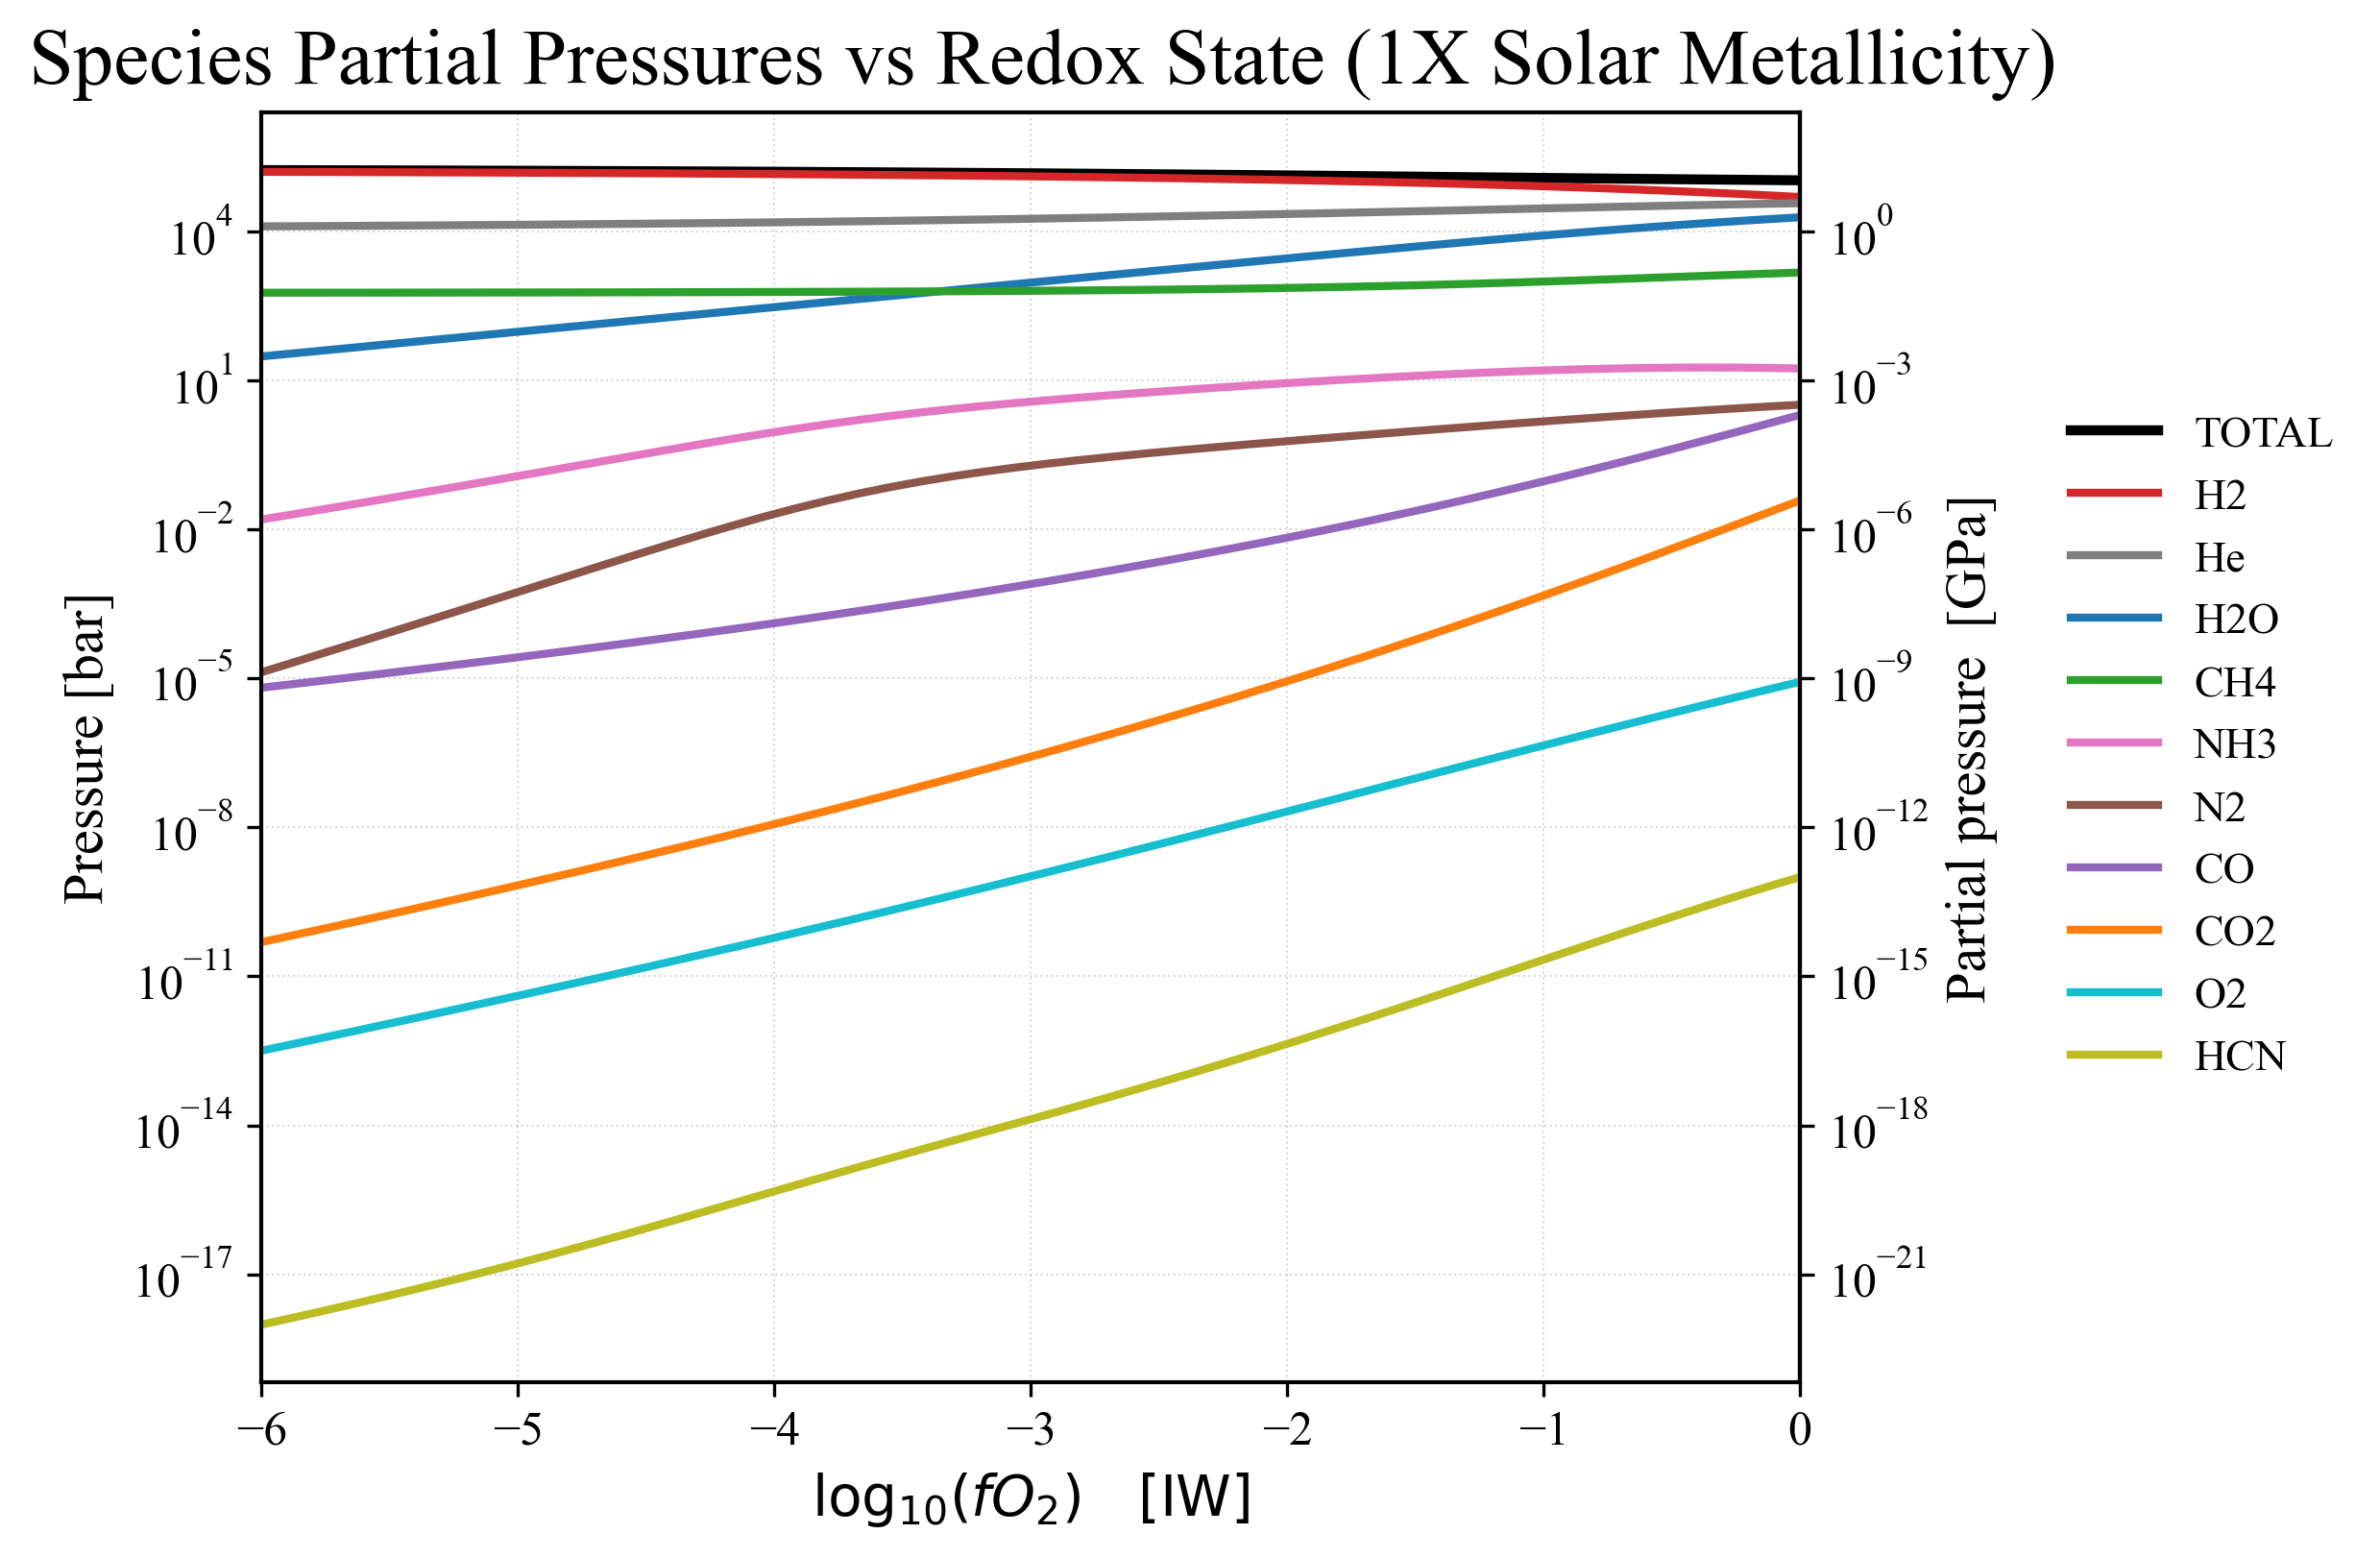

In [11]:
plot_fugacity_vs_fO2("LASTFO21REAL.xlsx")

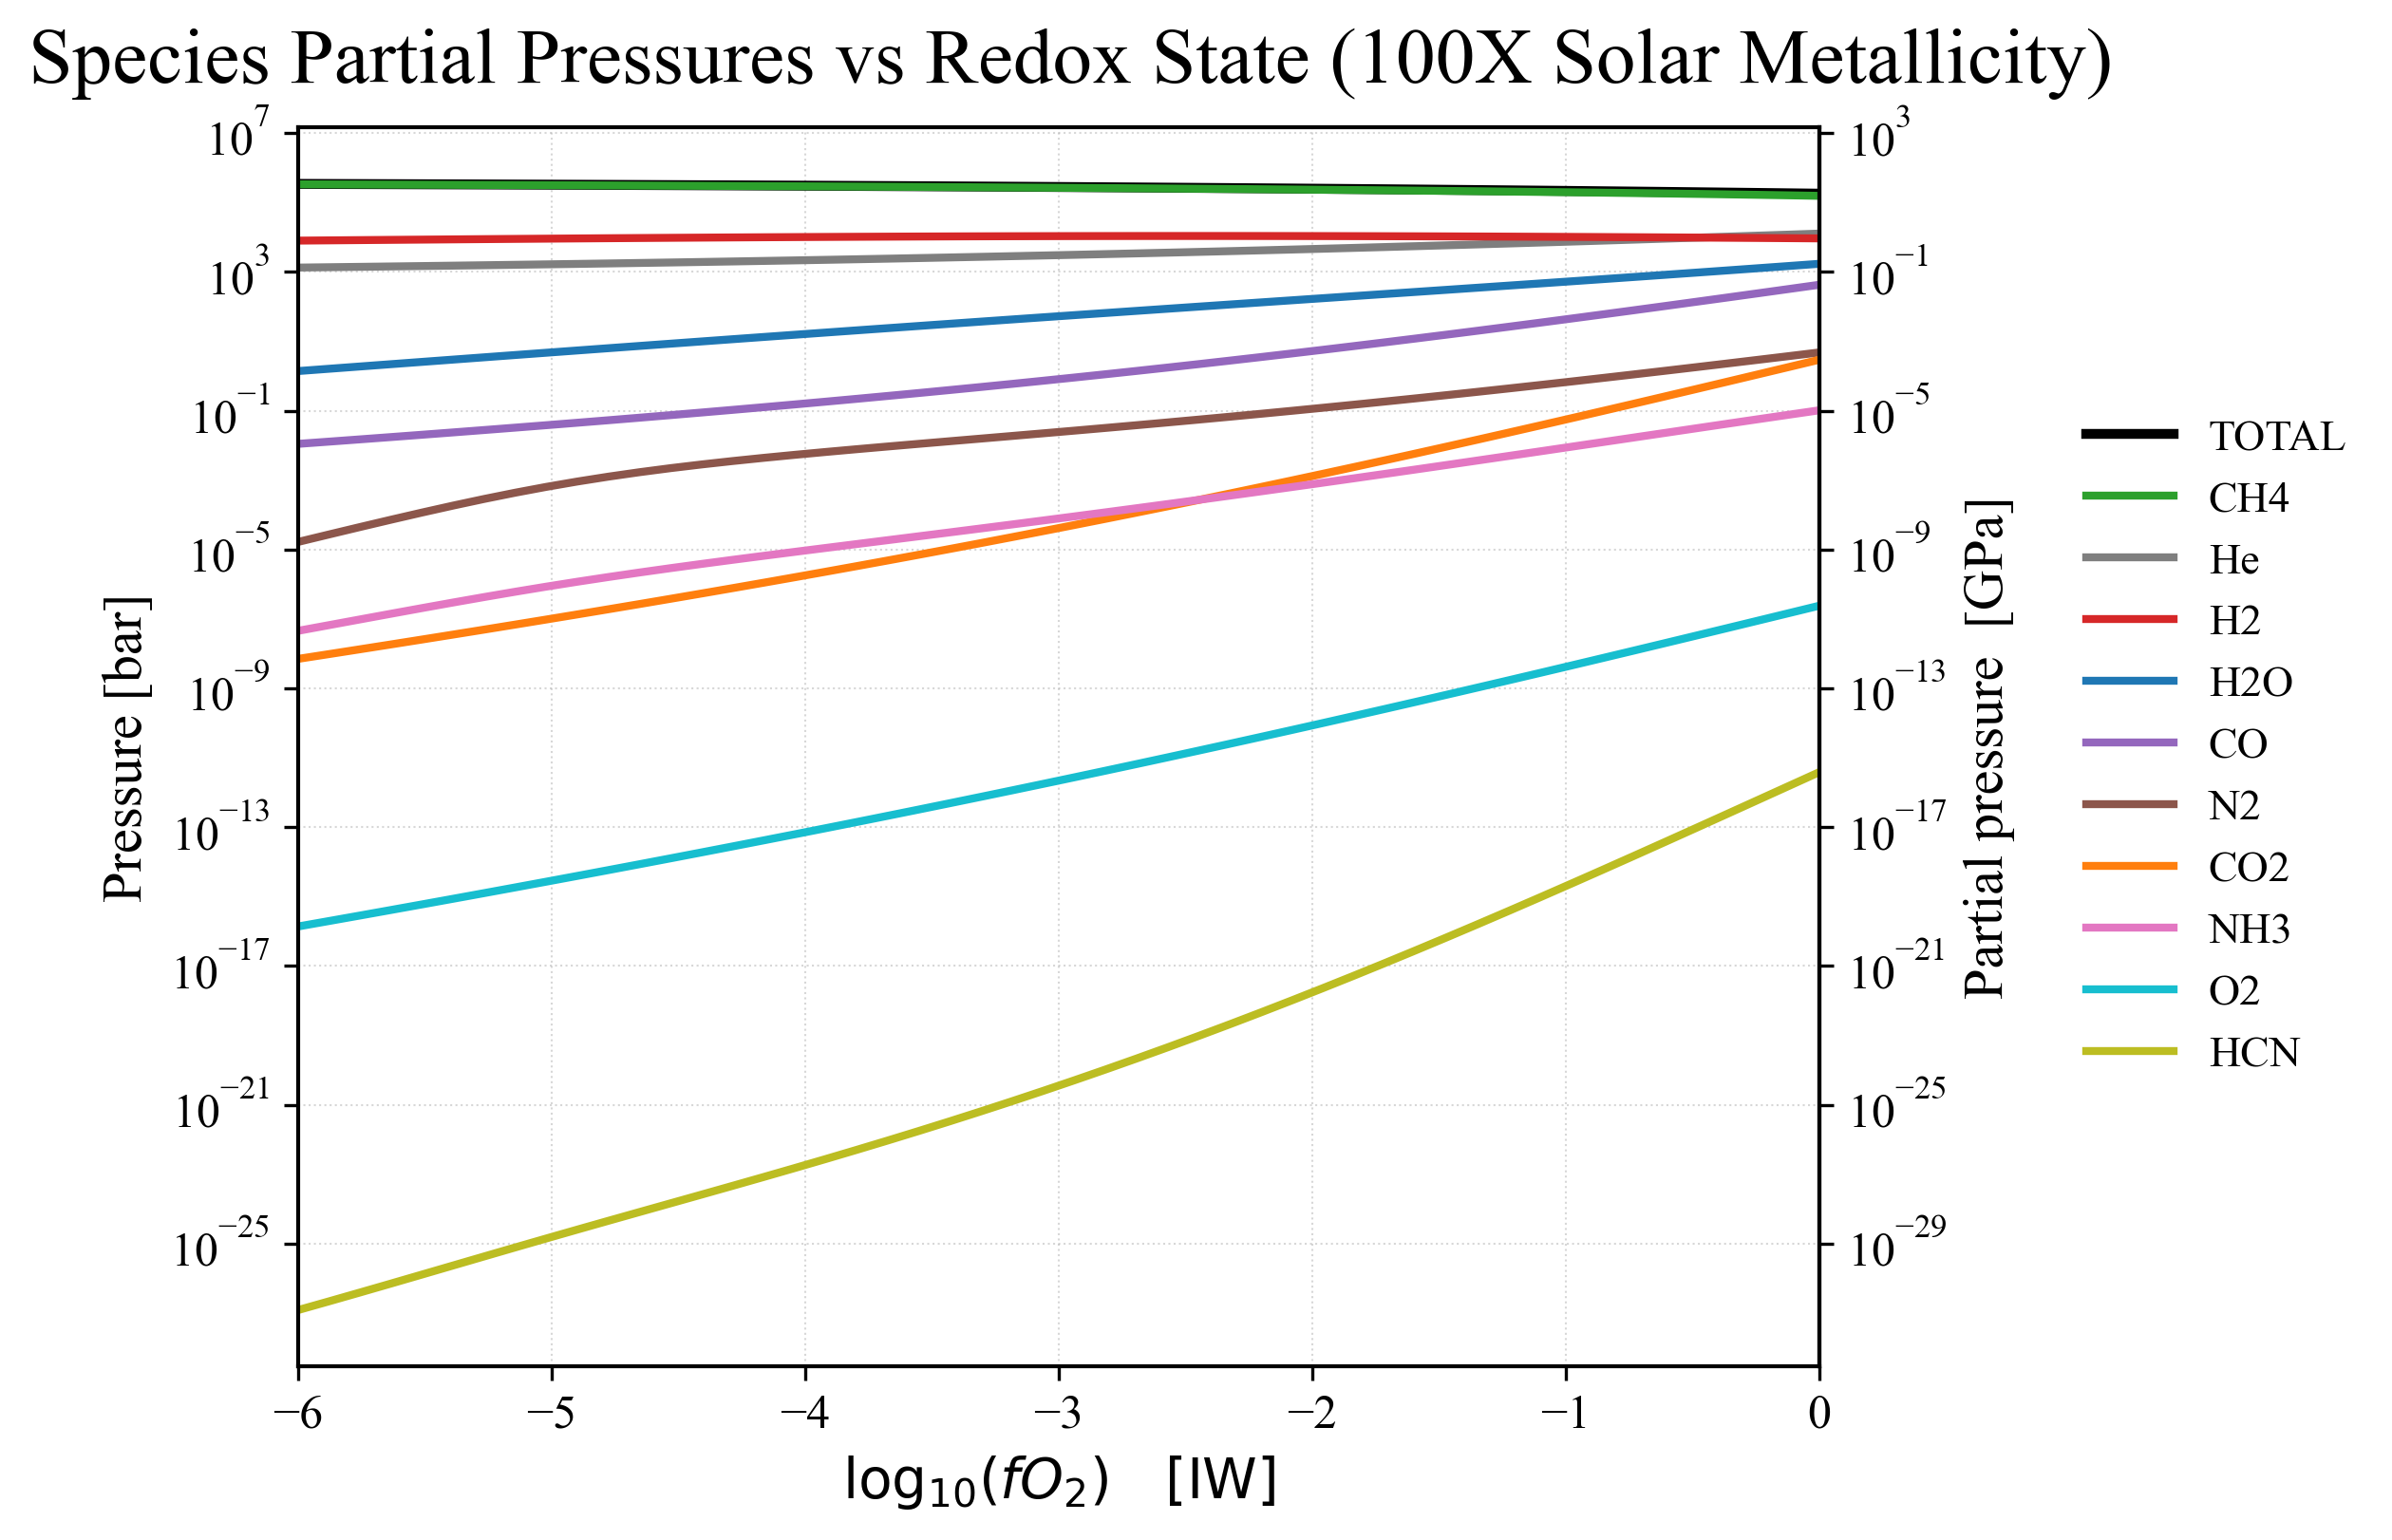

In [13]:
plot_fugacity_vs_fO2("LASTFO21REAL_NEW_IDK.xlsx")

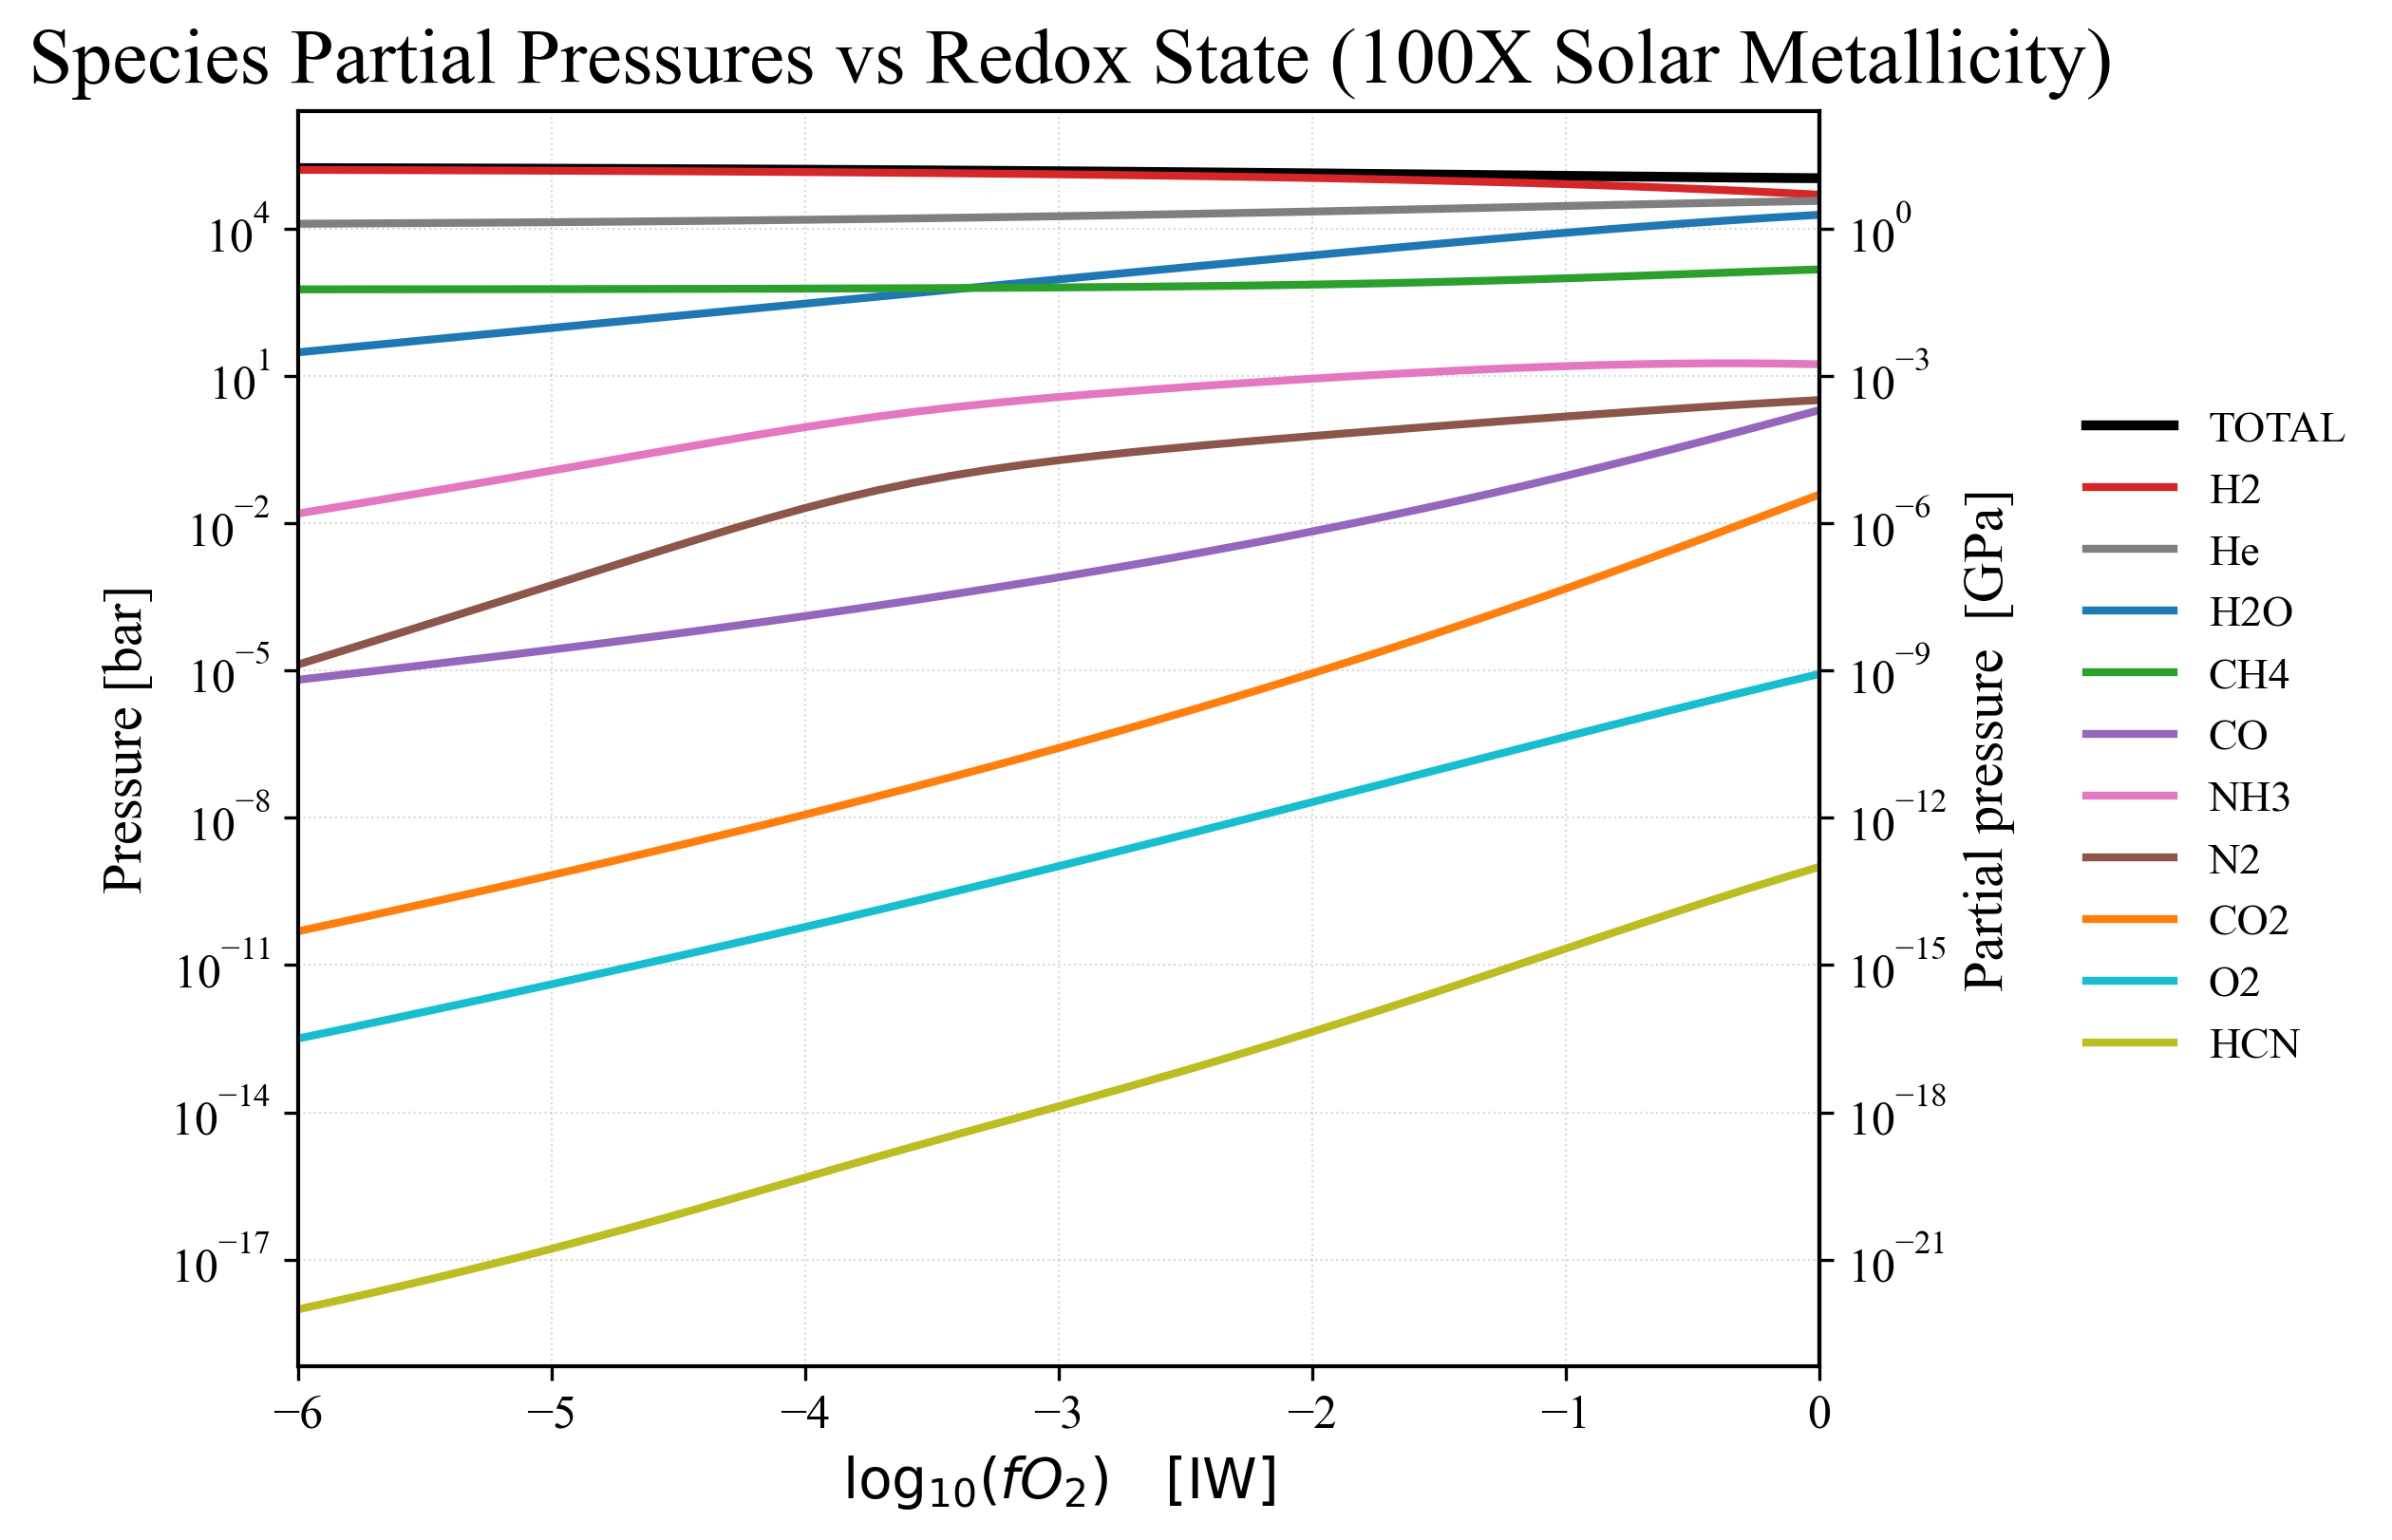

In [14]:
plot_fugacity_vs_fO2("SUBNEPTUNE_REALFO2NEW.xlsx")

/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_9125/651416283.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = get_cmap("tab10").colors


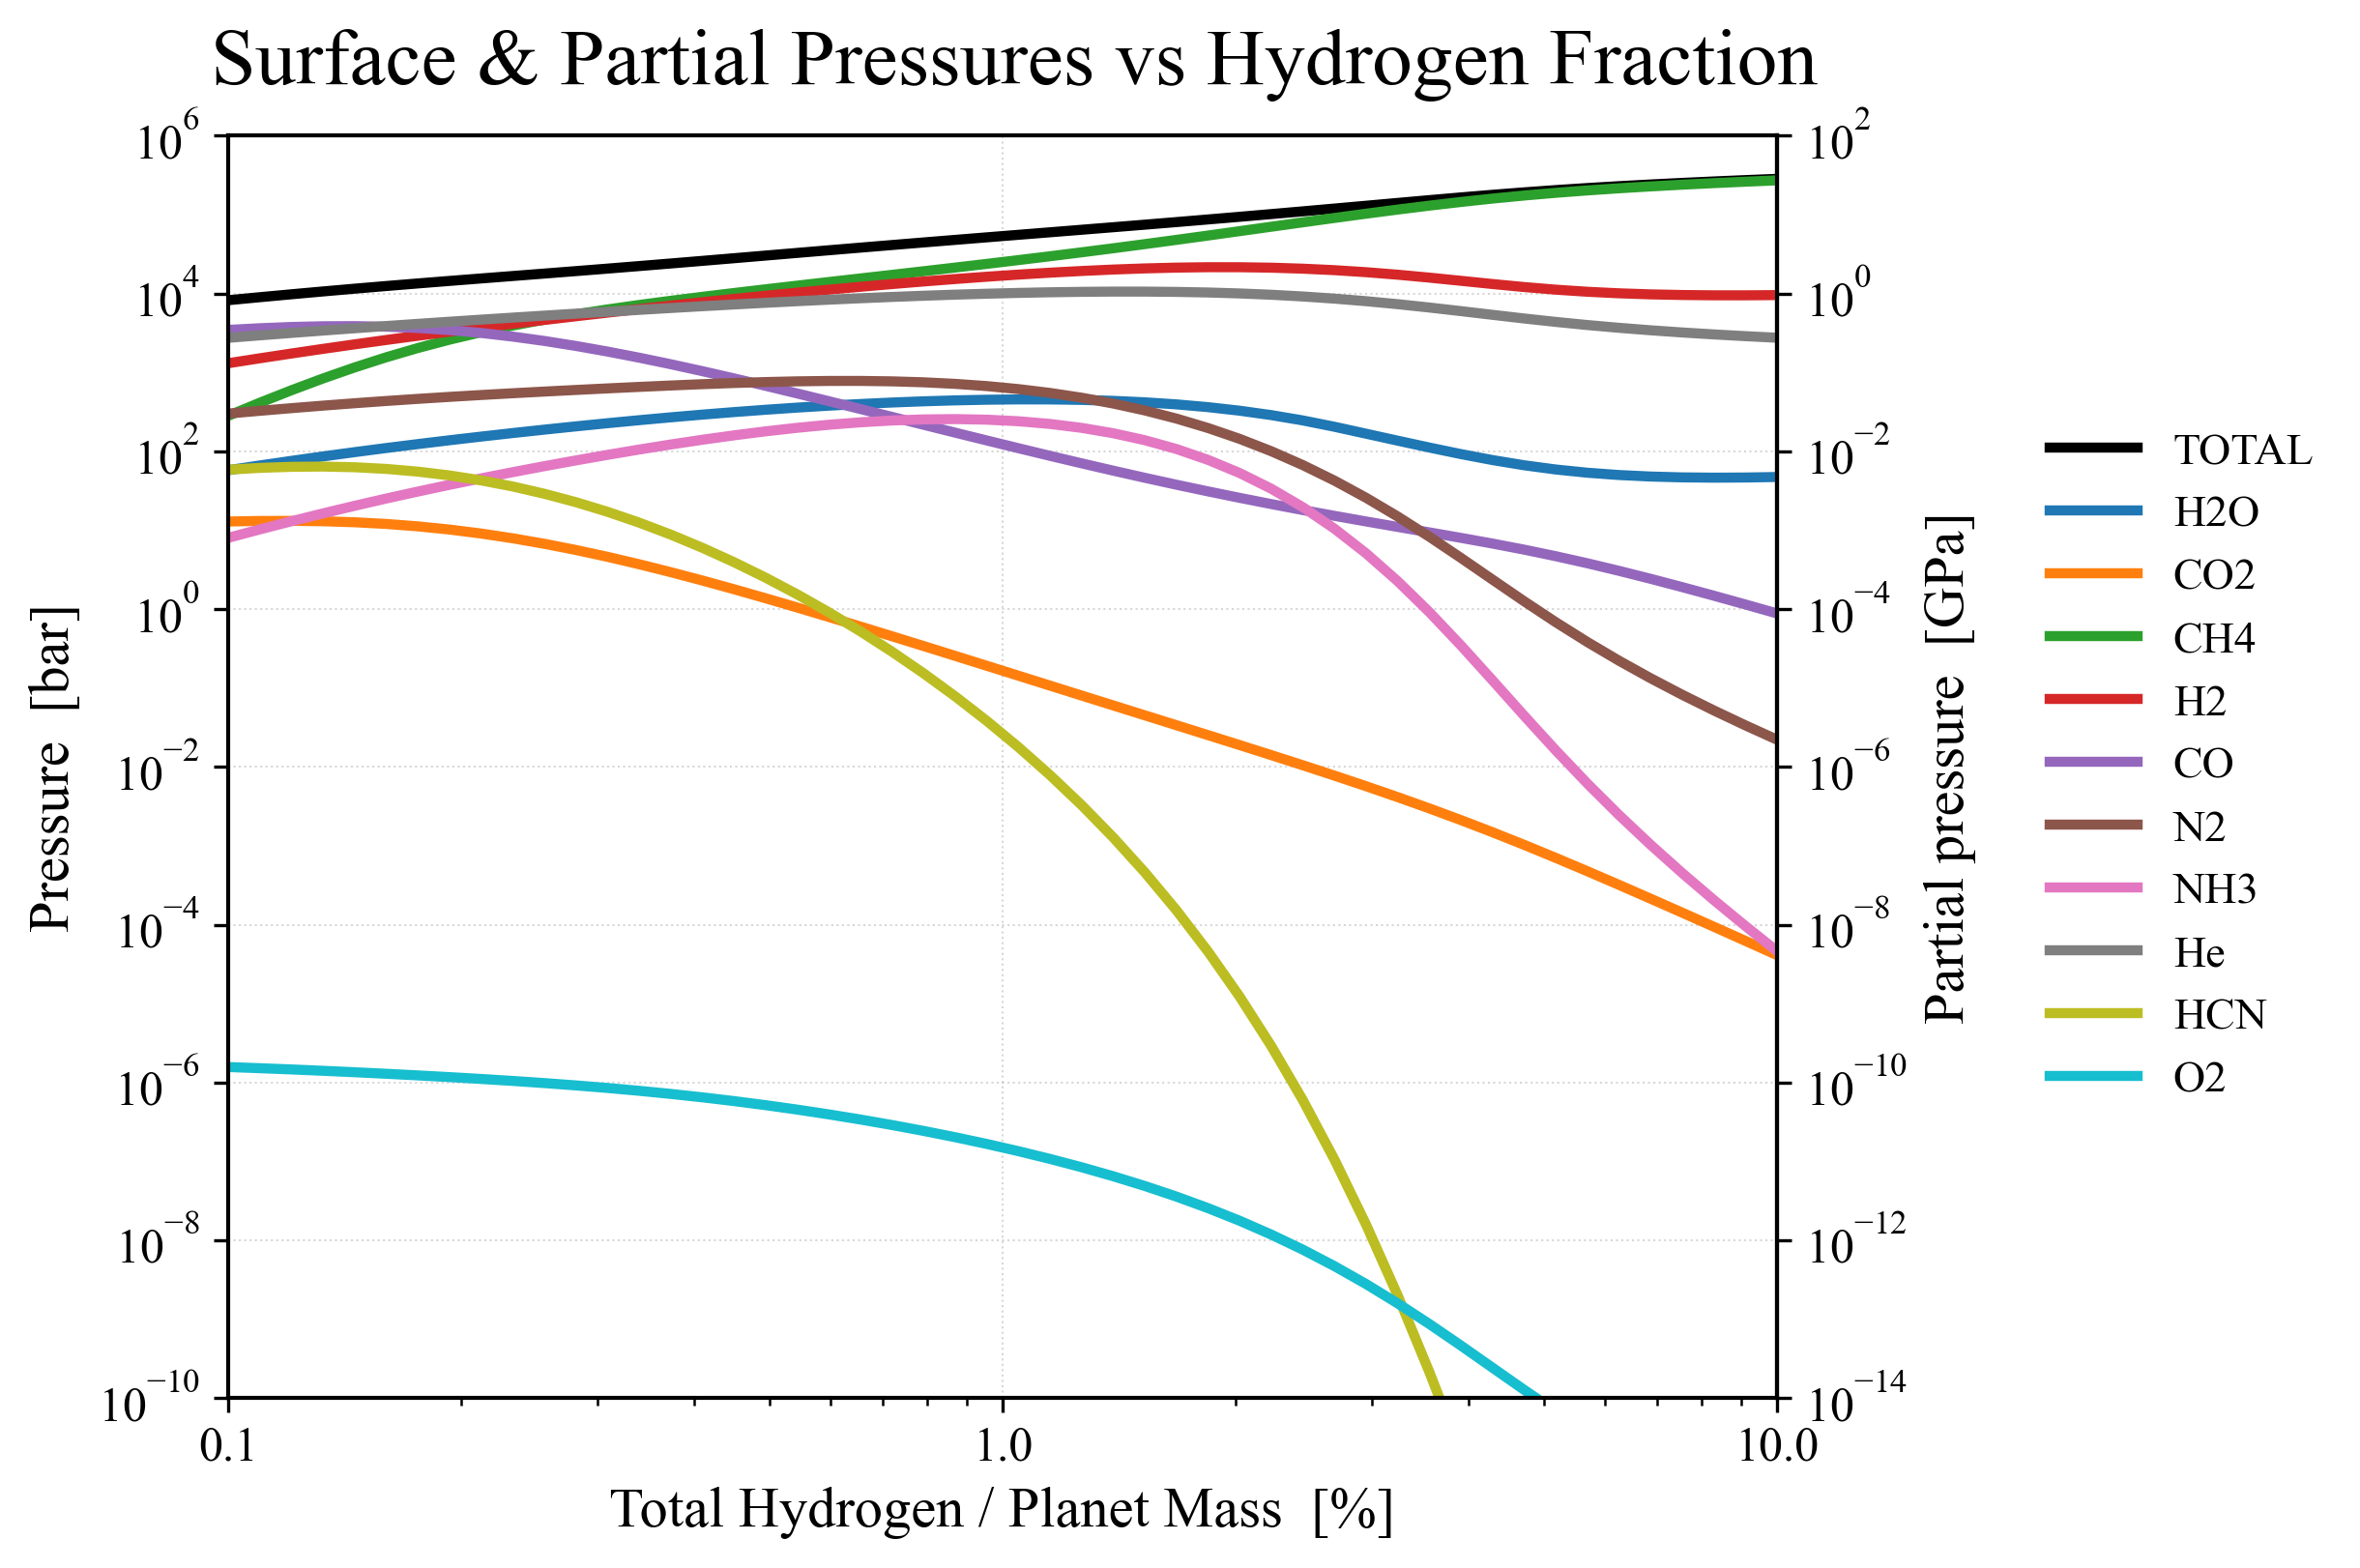

In [93]:
plot_pressure_vs_H_fraction("THEREALEST.xlsx")

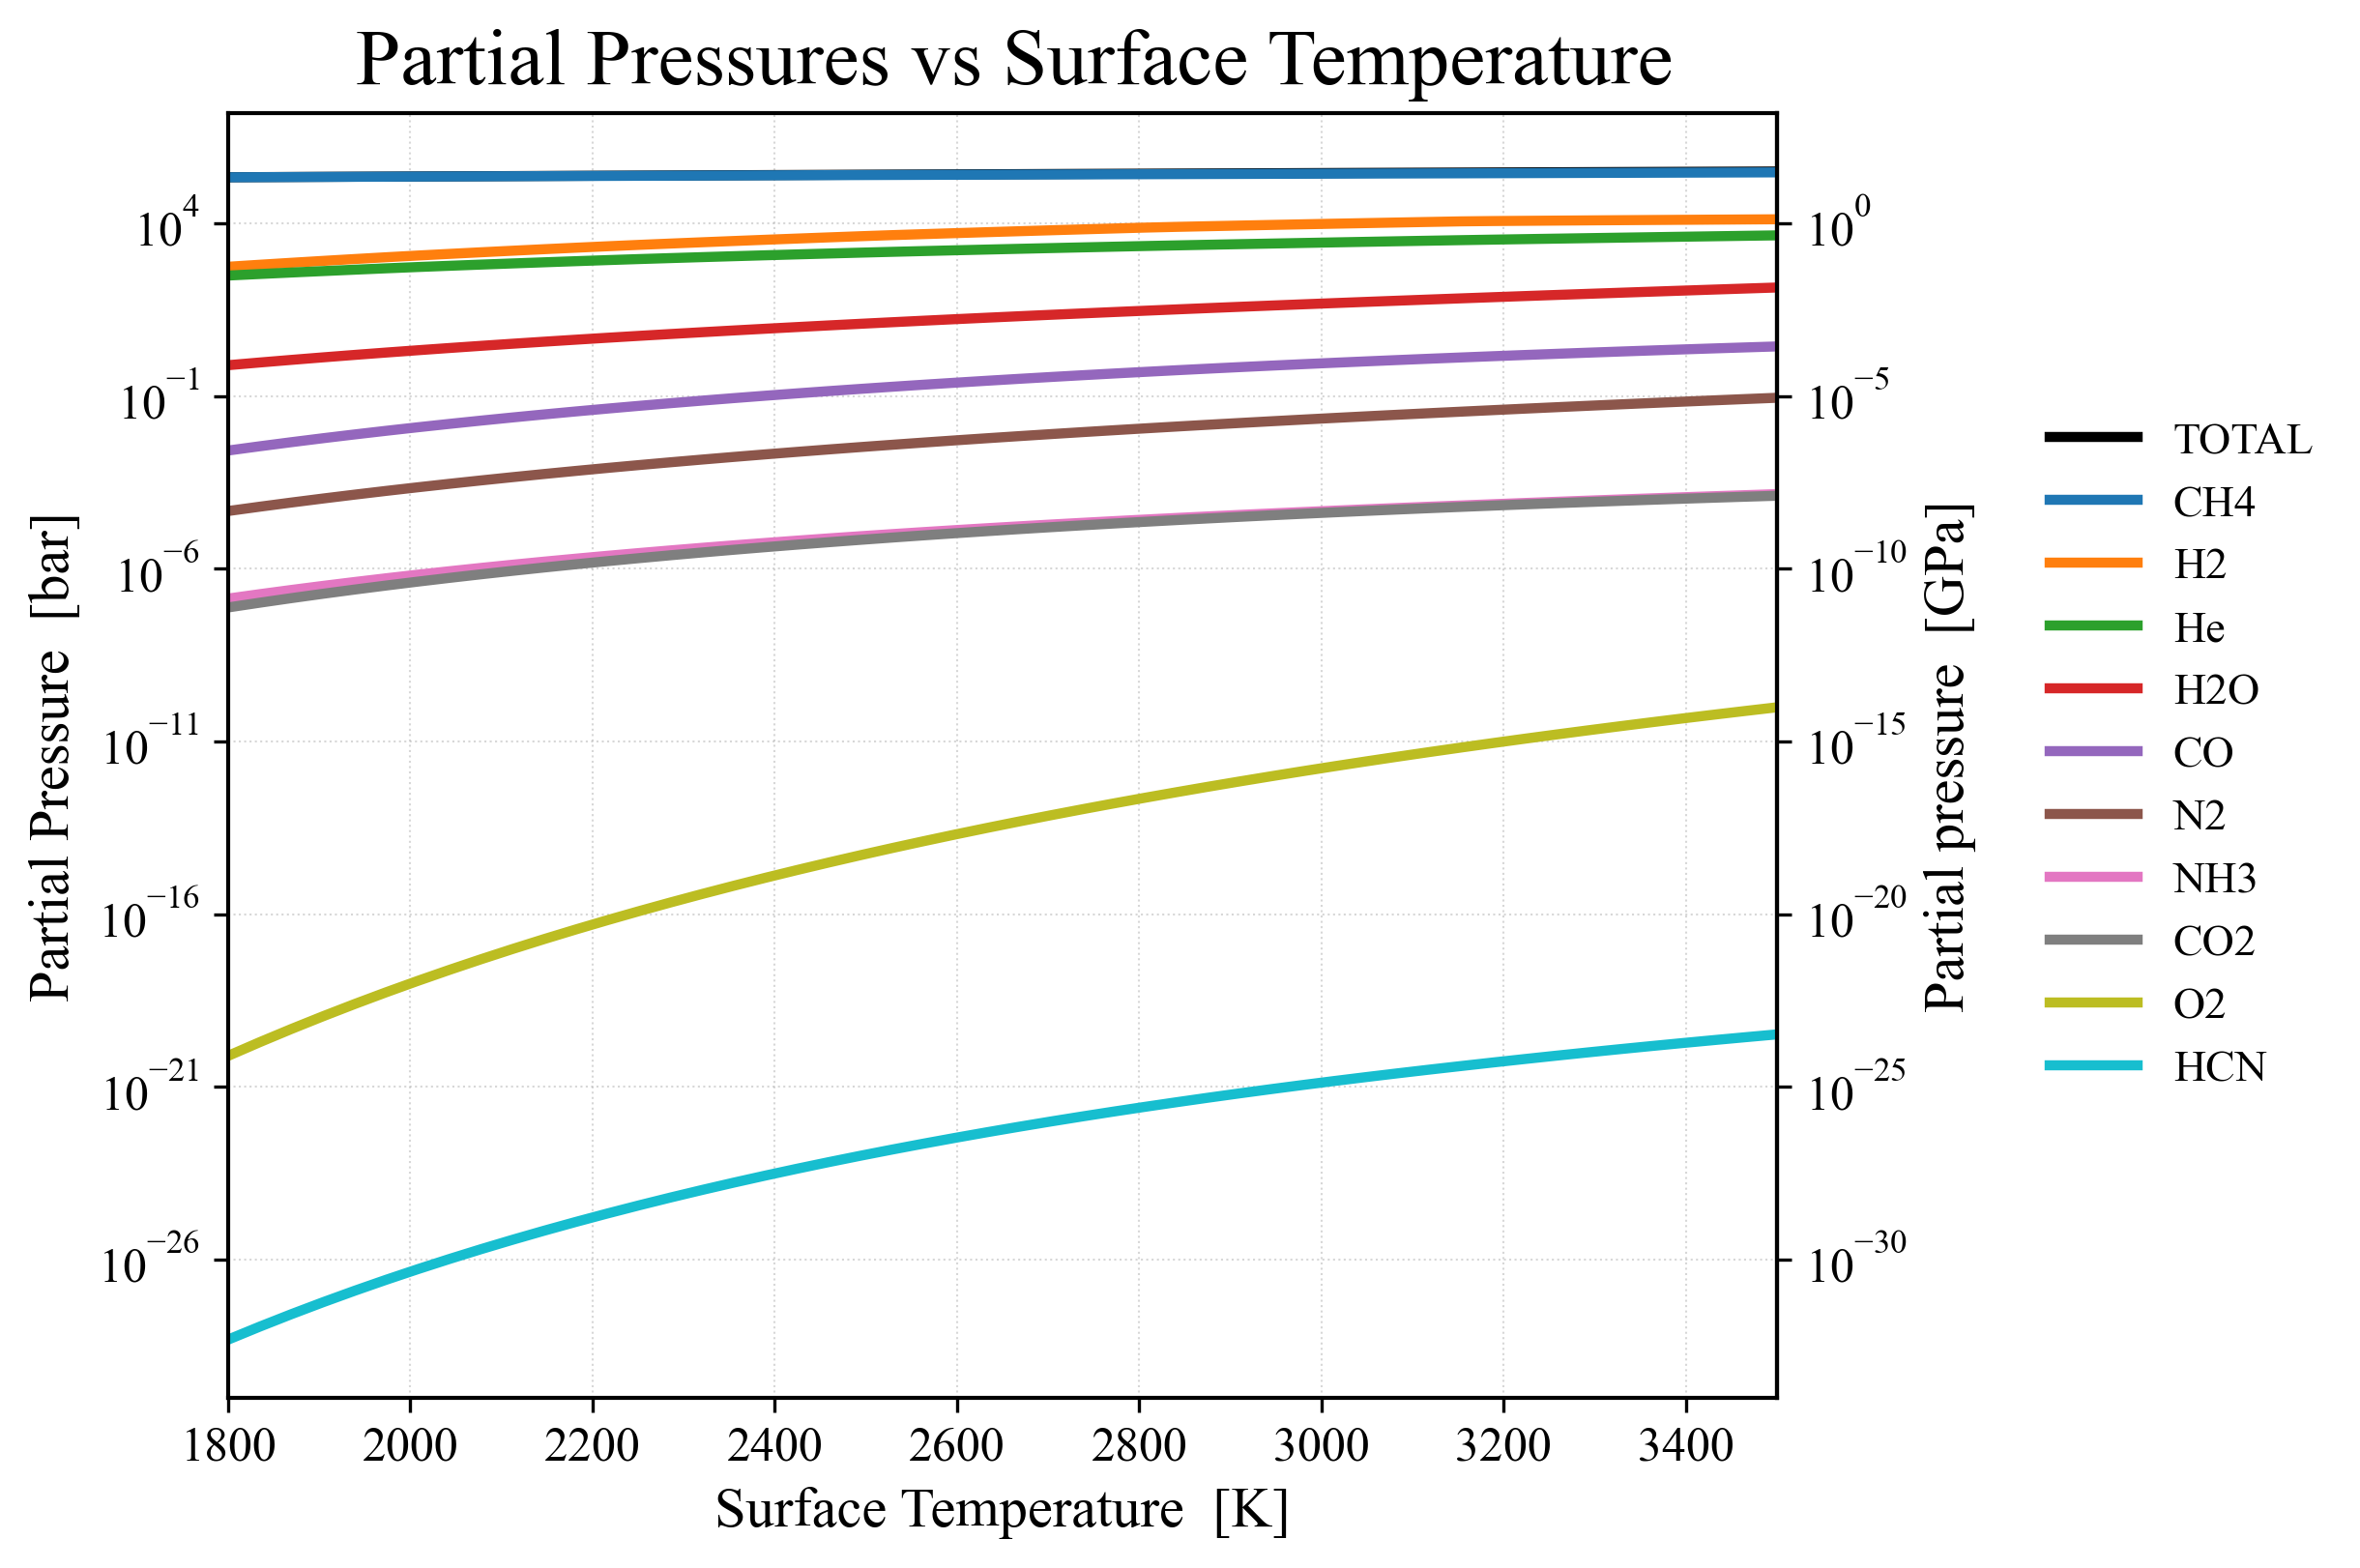

In [32]:
plot_pressure_vs_temperature("MOOOOOR.xlsx")

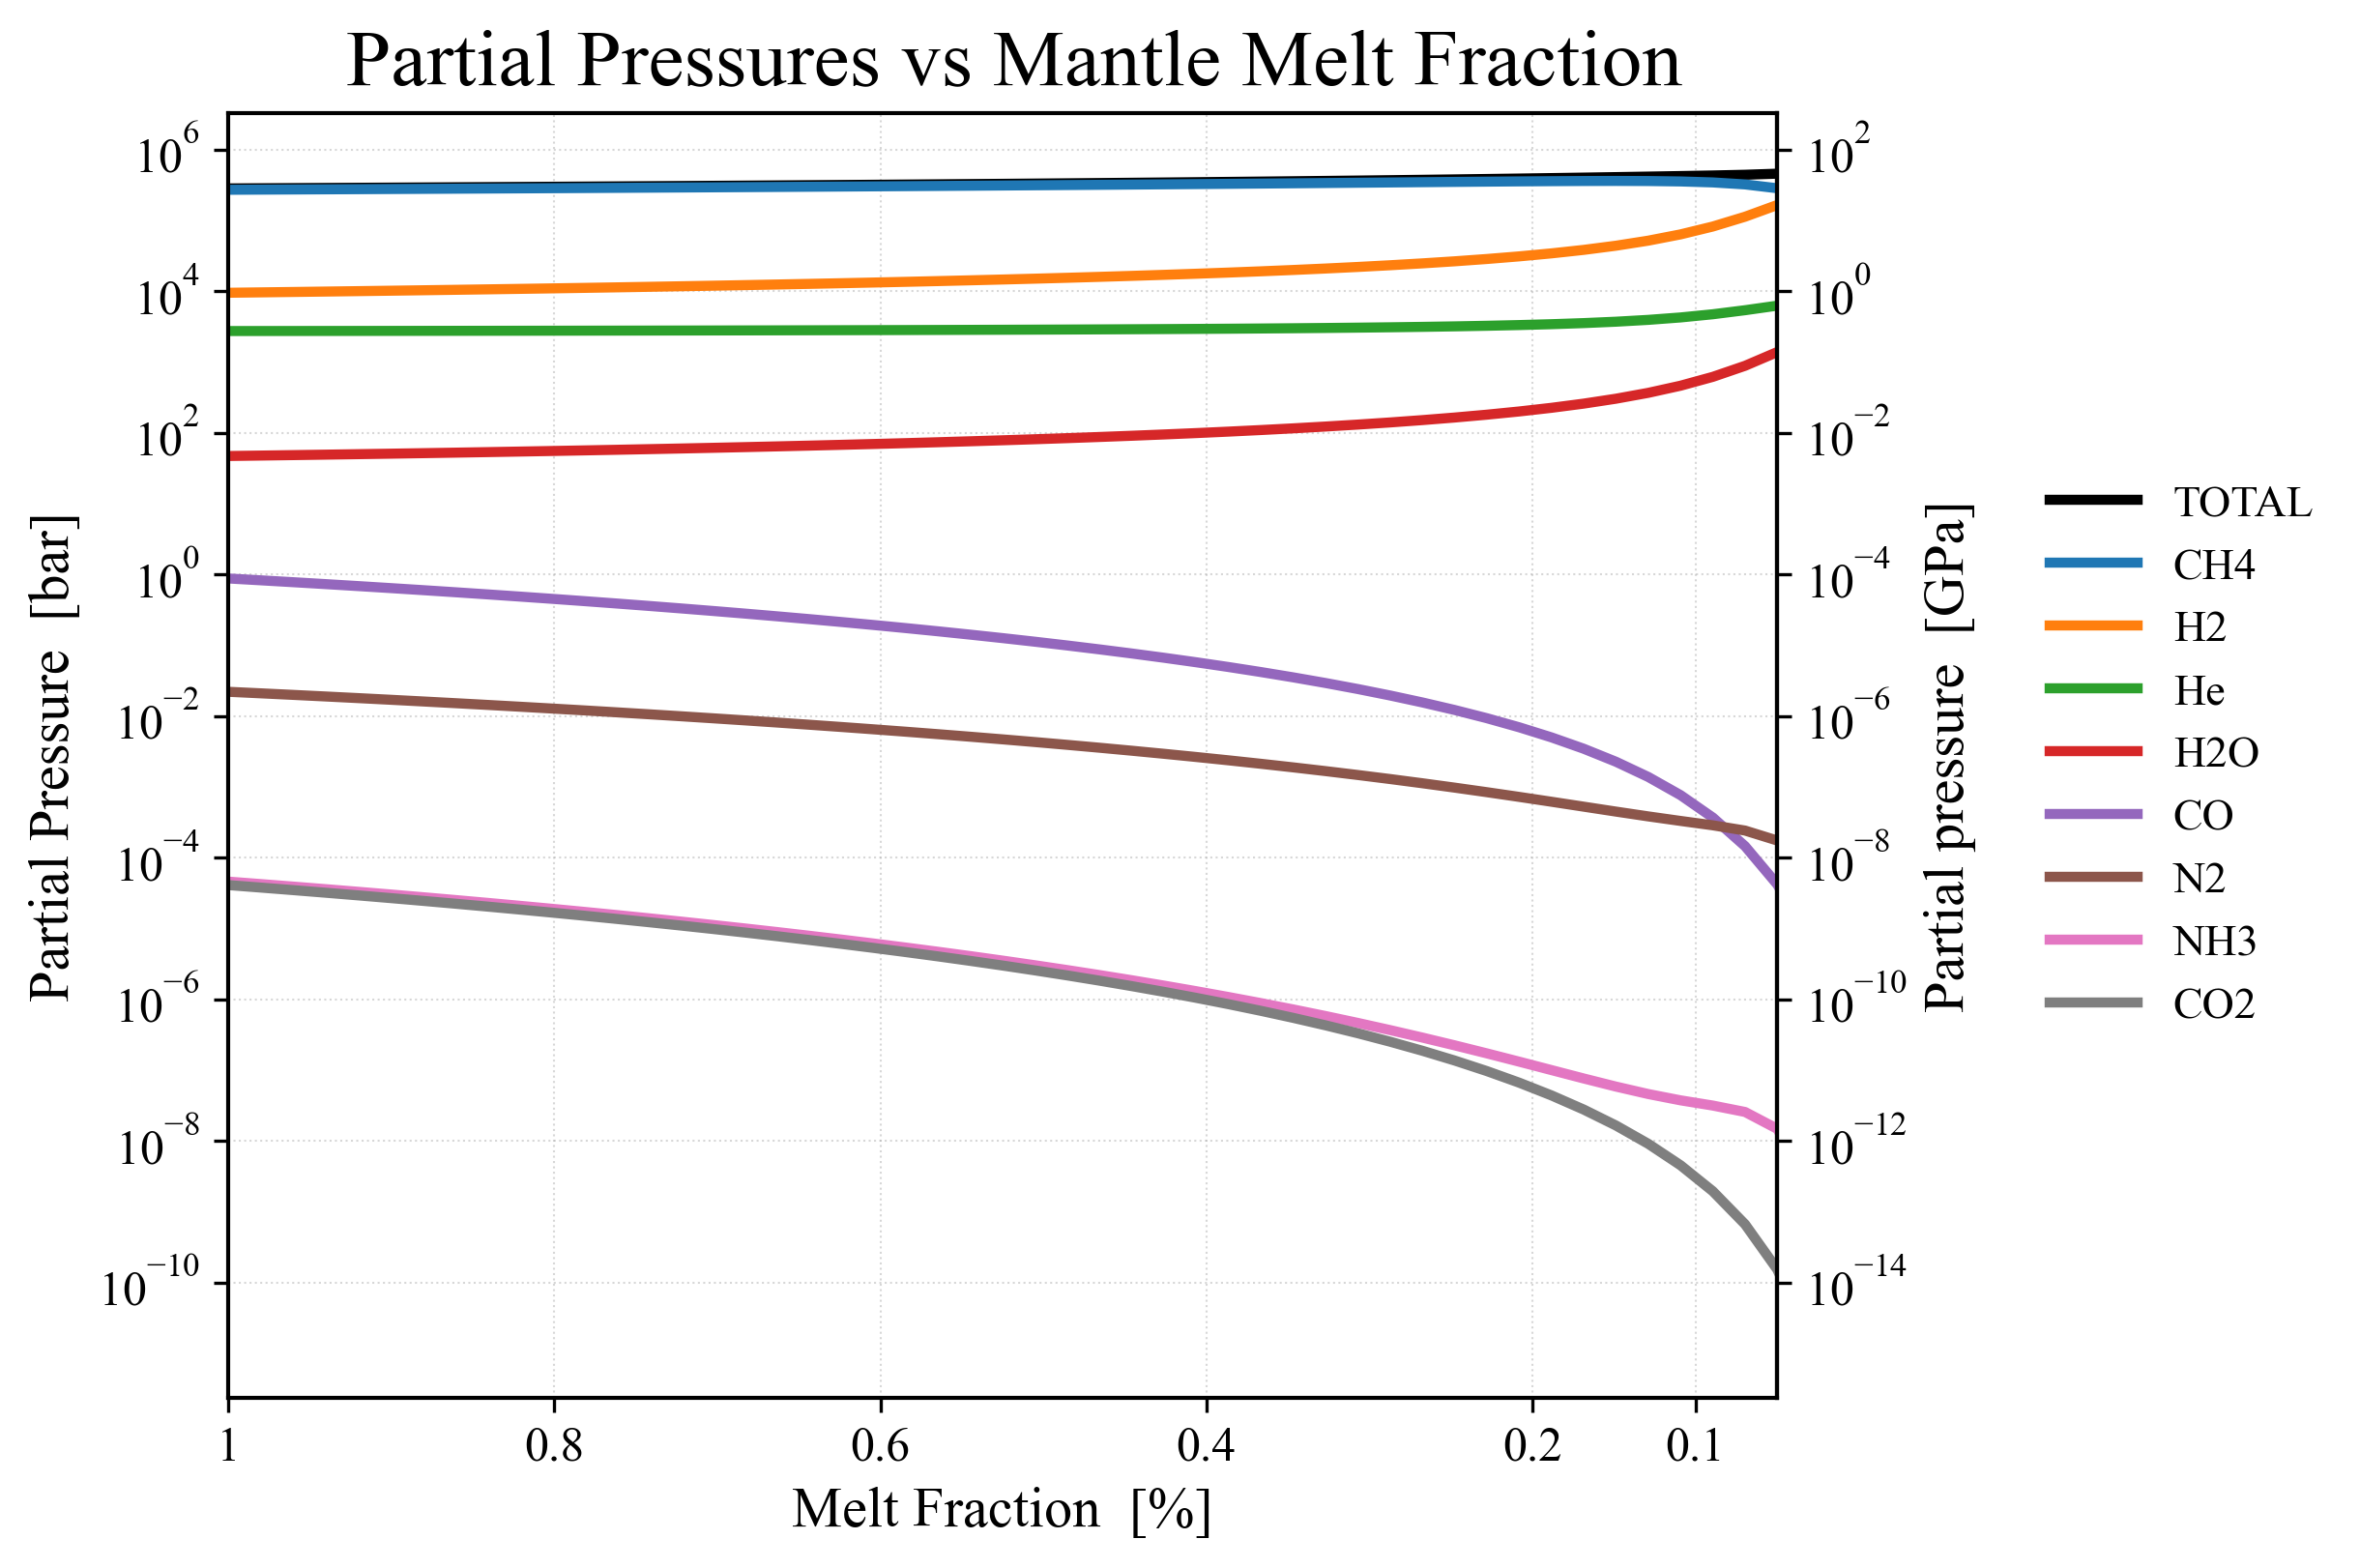

In [63]:
plot_pressure_vs_meltfraction("MELTSBEITCHNEW.xlsx")

In [52]:
def plot_pressure_vs_meltfraction_symlog(file):
    set_master_nature_style()

    CANDIDATE_SHEETS = [
        'H2O_g','CO2_g','CH4_g','H2_g','CO_g',
        'N2_g','H3N_g','He_g','CHN_g', "O2_g"
    ]

    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N": return "NH3"
        if name == "CHN": return "HCN"
        return name

    # Load melt fraction
    planet = pd.read_excel(file, sheet_name="planet")
    X = planet["mantle_melt_fraction"].to_numpy()
    order = np.argsort(X)
    X = X[order]

    # Detect gas sheets
    xls = pd.ExcelFile(file)
    available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

    # Collect species pressures
    species_pressures = {}
    for s in available:
        df = pd.read_excel(file, sheet_name=s)
        if "pressure" in df.columns:
            species_pressures[s] = df["pressure"].to_numpy()[order]

    # Total atmospheric pressure
    atm = pd.read_excel(file, sheet_name="atmosphere")
    Ptot = atm["pressure"].to_numpy()[order]

    # Sort species by importance
    sorted_species = sorted(
        species_pressures.keys(),
        key=lambda k: np.nanmax(species_pressures[k]),
        reverse=True
    )

    # -------------------- PLOT --------------------
    fig, ax = plt.subplots(figsize=(8,5), dpi=300, layout="constrained")

    # Plot total
    ax.plot(X, Ptot, lw=2.5, color="black", label="TOTAL")

    # Plot species curves
    for s in sorted_species:
        ax.plot(X, species_pressures[s], lw=2, label=map_name(s))

    # Labels
    ax.set_xlabel("Melt Fraction [%]")
    ax.set_ylabel("Partial Pressure [bar]")

    # Reverse X
    ax.set_xlim([0.05, 1])
    ax.invert_xaxis()
    ax.set_xticks([1.0,0.8,0.6,0.4,0.2,0.1])

    # *** OFFSET LOG SCALE ***
    ax.set_yscale("symlog", linthresh=1e-40)  # <--- key line
    ax.set_ylim(1e-40, 1e8)

    apply_secondary_gpa_axis(ax)

    apply_master_layout(
        fig, ax,
        "Partial Pressures vs Mantle Melt Fraction (symlog scale)"
    )

    plt.legend()
    plt.show()


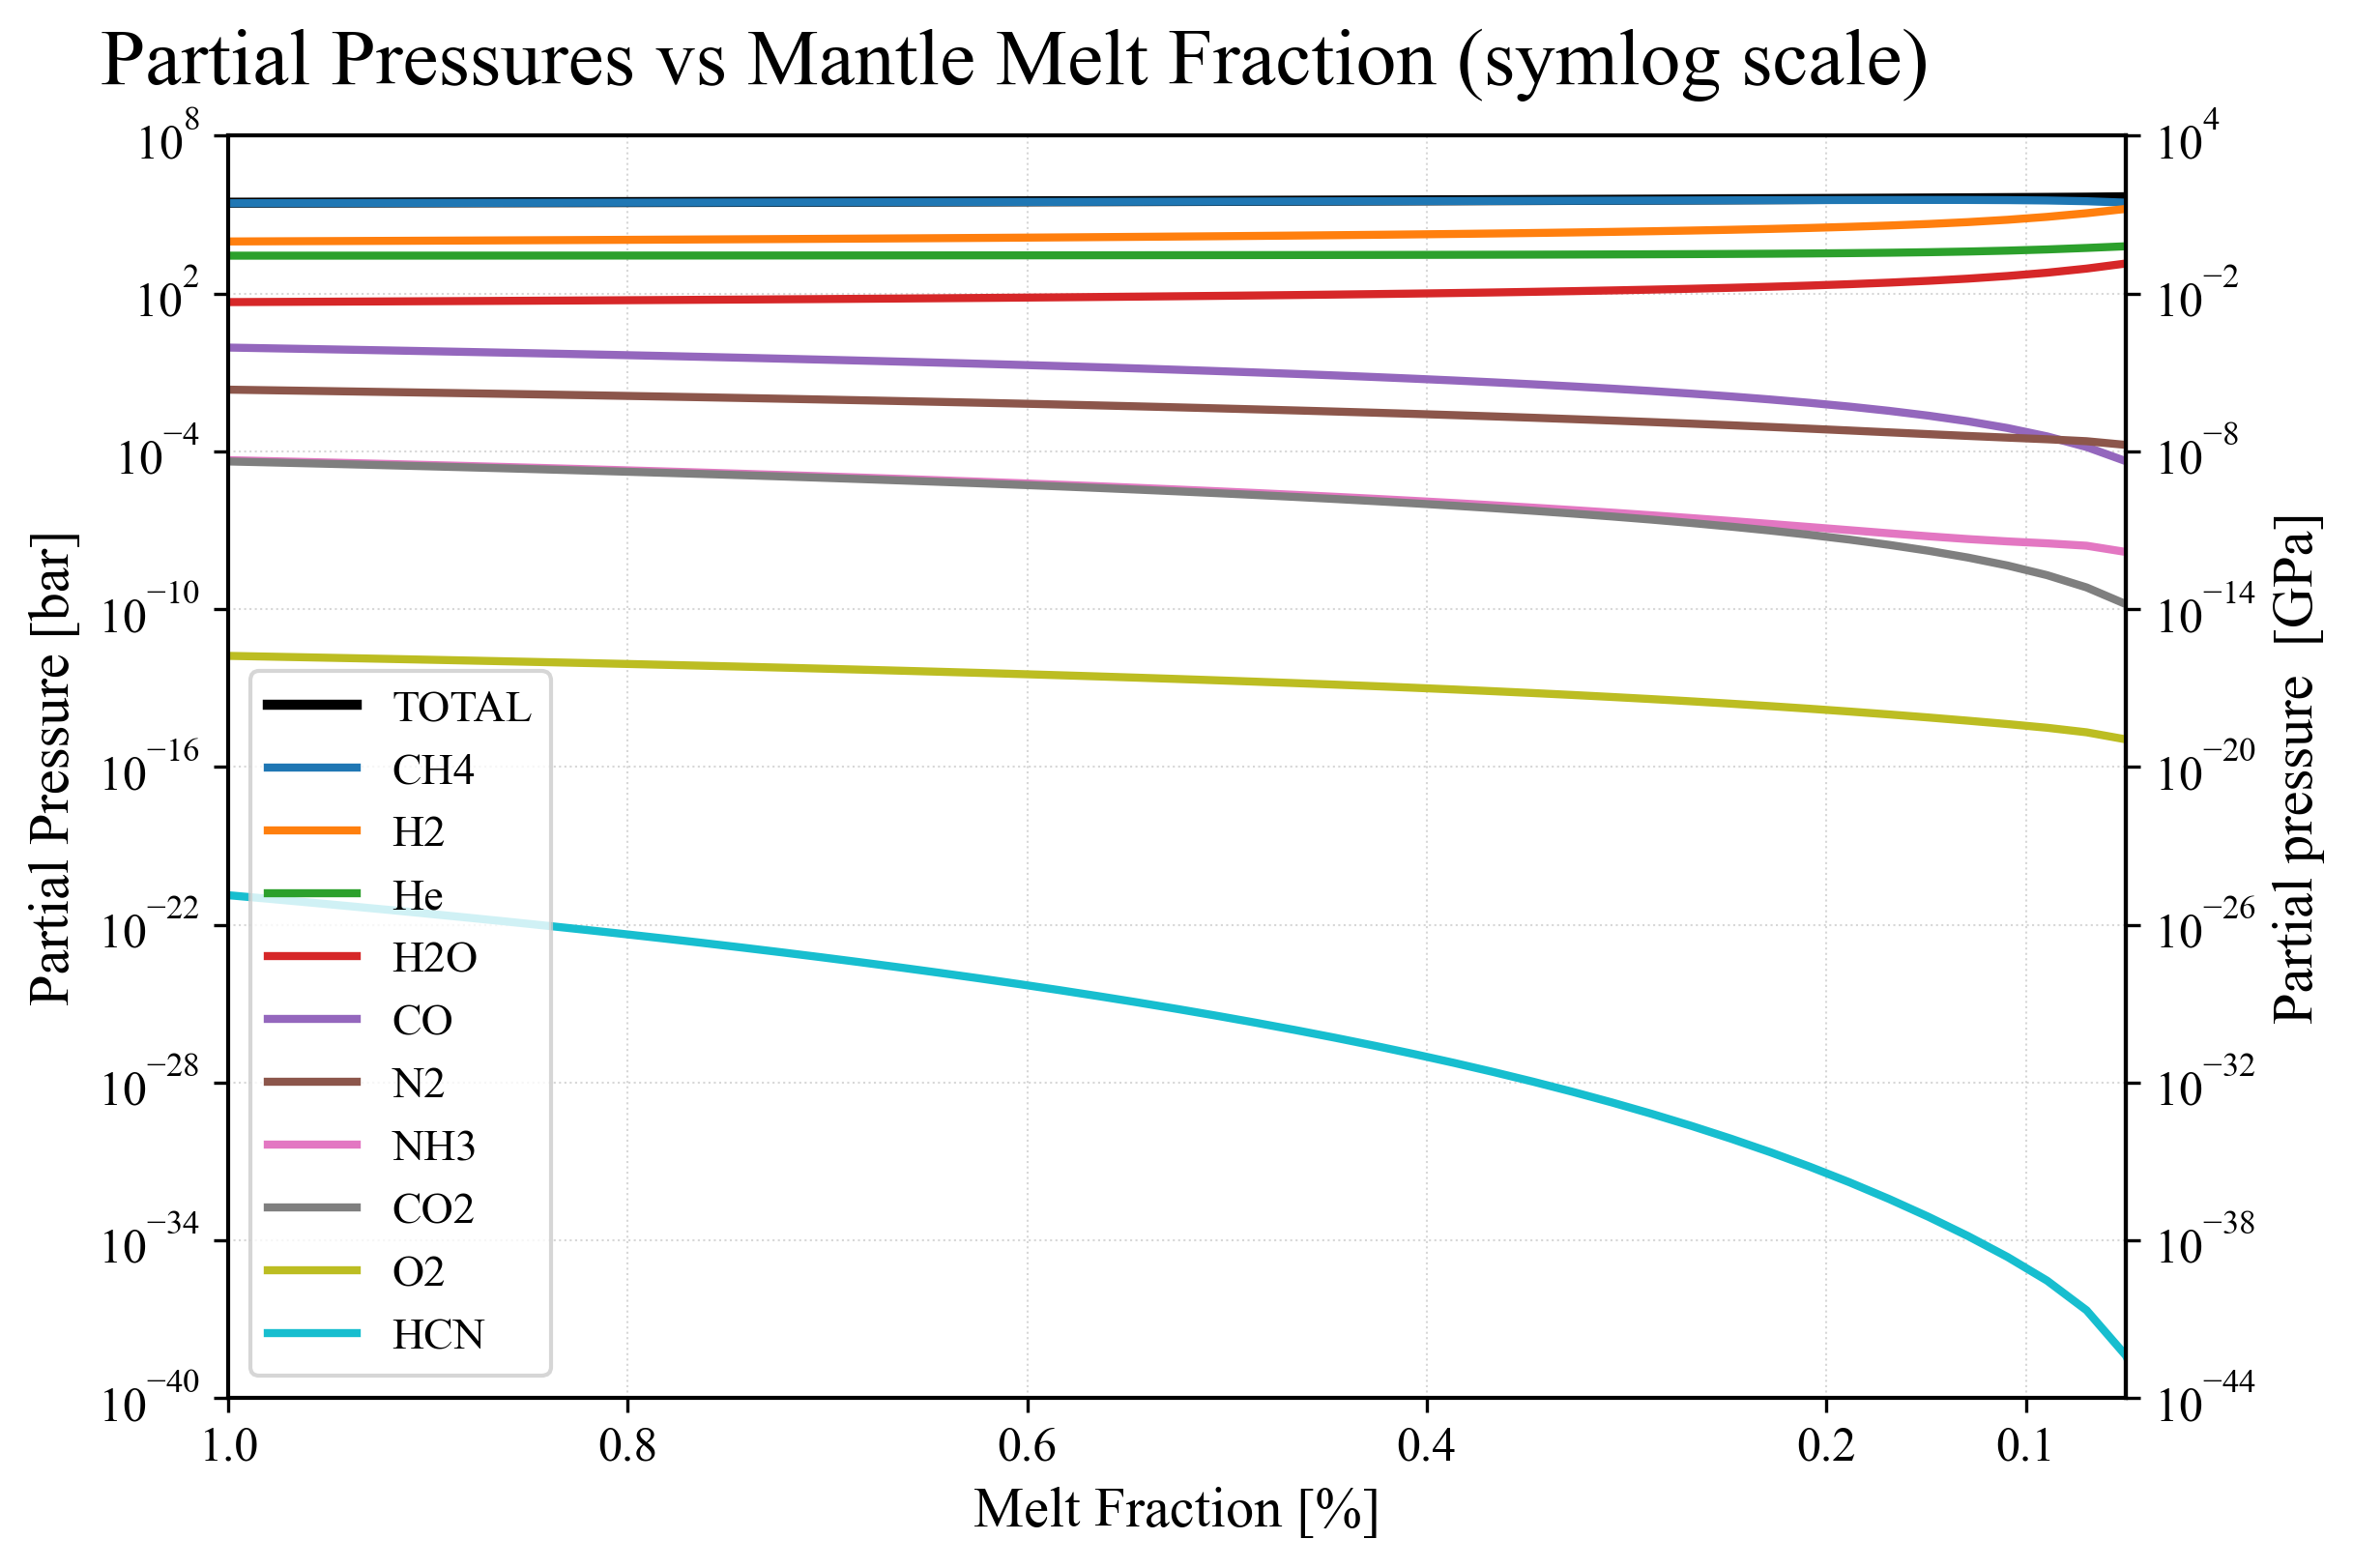

In [53]:
plot_pressure_vs_meltfraction_symlog("MELTSBEITCHNEW.xlsx")

In [64]:
def plot_pressure_vs_meltfraction_broken_axis(file):
    set_master_nature_style()

    CANDIDATE_SHEETS = [
        'H2O_g','CO2_g','CH4_g','H2_g','CO_g',
        'N2_g','H3N_g','He_g','CHN_g', "O2_g"
    ]

    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N": return "NH3"
        if name == "CHN": return "HCN"
        return name

    # Load X
    planet = pd.read_excel(file, sheet_name="planet")
    X = planet["mantle_melt_fraction"].to_numpy()
    order = np.argsort(X)
    X = X[order]

    # Detect species
    xls = pd.ExcelFile(file)
    available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

    # Load pressures
    species_pressures = {}
    for s in available:
        df = pd.read_excel(file, sheet_name=s)
        if "pressure" in df.columns:
            species_pressures[s] = df["pressure"].to_numpy()[order]

    # Total
    atm = pd.read_excel(file, sheet_name="atmosphere")
    Ptot = atm["pressure"].to_numpy()[order]

    # Sort species
    sorted_species = sorted(
        species_pressures.keys(),
        key=lambda k: np.nanmax(species_pressures[k]),
        reverse=True
    )

    # --------------------------------------------------
    #   BROKEN AXIS LAYOUT
    # --------------------------------------------------
    fig, (ax_upper, ax_lower) = plt.subplots(
        2, 1, sharex=True, figsize=(8,7), dpi=300,
        height_ratios=[3,1], layout="constrained"
    )

    # Upper limits (high pressures)
    upper_min, upper_max = 1e-10, 1e6
    # Lower limits (tiny pressures)
    lower_min, lower_max = 1e-40, 1e-10

    # ---- UPPER PANEL ----
    ax_upper.plot(X, Ptot, lw=2.5, color="black", label="TOTAL")
    for s in sorted_species:
        ax_upper.plot(X, species_pressures[s], lw=2)
    ax_upper.set_yscale("log")
    ax_upper.set_ylim(upper_min, upper_max)
    ax_upper.set_ylabel("Partial Pressure [bar]")
    ax_upper.legend(ncol=2, fontsize=8)

    # ---- LOWER PANEL ----
    for s in sorted_species:
        ax_lower.plot(X, species_pressures[s], lw=2)
    ax_lower.set_yscale("log")
    ax_lower.set_ylim(lower_min, lower_max)
    ax_lower.set_xlabel("Melt Fraction [%]")
    ax_lower.set_ylabel("Trace\nSpecies")

    # Reverse X-axis
    ax_lower.set_xlim([0.1, 1])
    ax_lower.invert_xaxis()
    ax_lower.set_xticks([1.0,0.8,0.6,0.4,0.2,0.1])

    # ---- Diagonal break marks ----
    d = 0.015
    kwargs = dict(transform=ax_upper.transAxes, color='k', clip_on=False)
    ax_upper.plot((-d, +d), (-d, +d), **kwargs)
    ax_upper.plot((1-d, 1+d), (-d, +d), **kwargs)

    kwargs = dict(transform=ax_lower.transAxes, color='k', clip_on=False)
    ax_lower.plot((-d, +d), (1-d, 1+d), **kwargs)
    ax_lower.plot((1-d, 1+d), (1-d, 1+d), **kwargs)

    # ---- Title / layout ----
    fig.suptitle("Partial Pressures vs Mantle Melt Fraction (broken log axis)")
    apply_secondary_gpa_axis(ax_upper)

    plt.show()


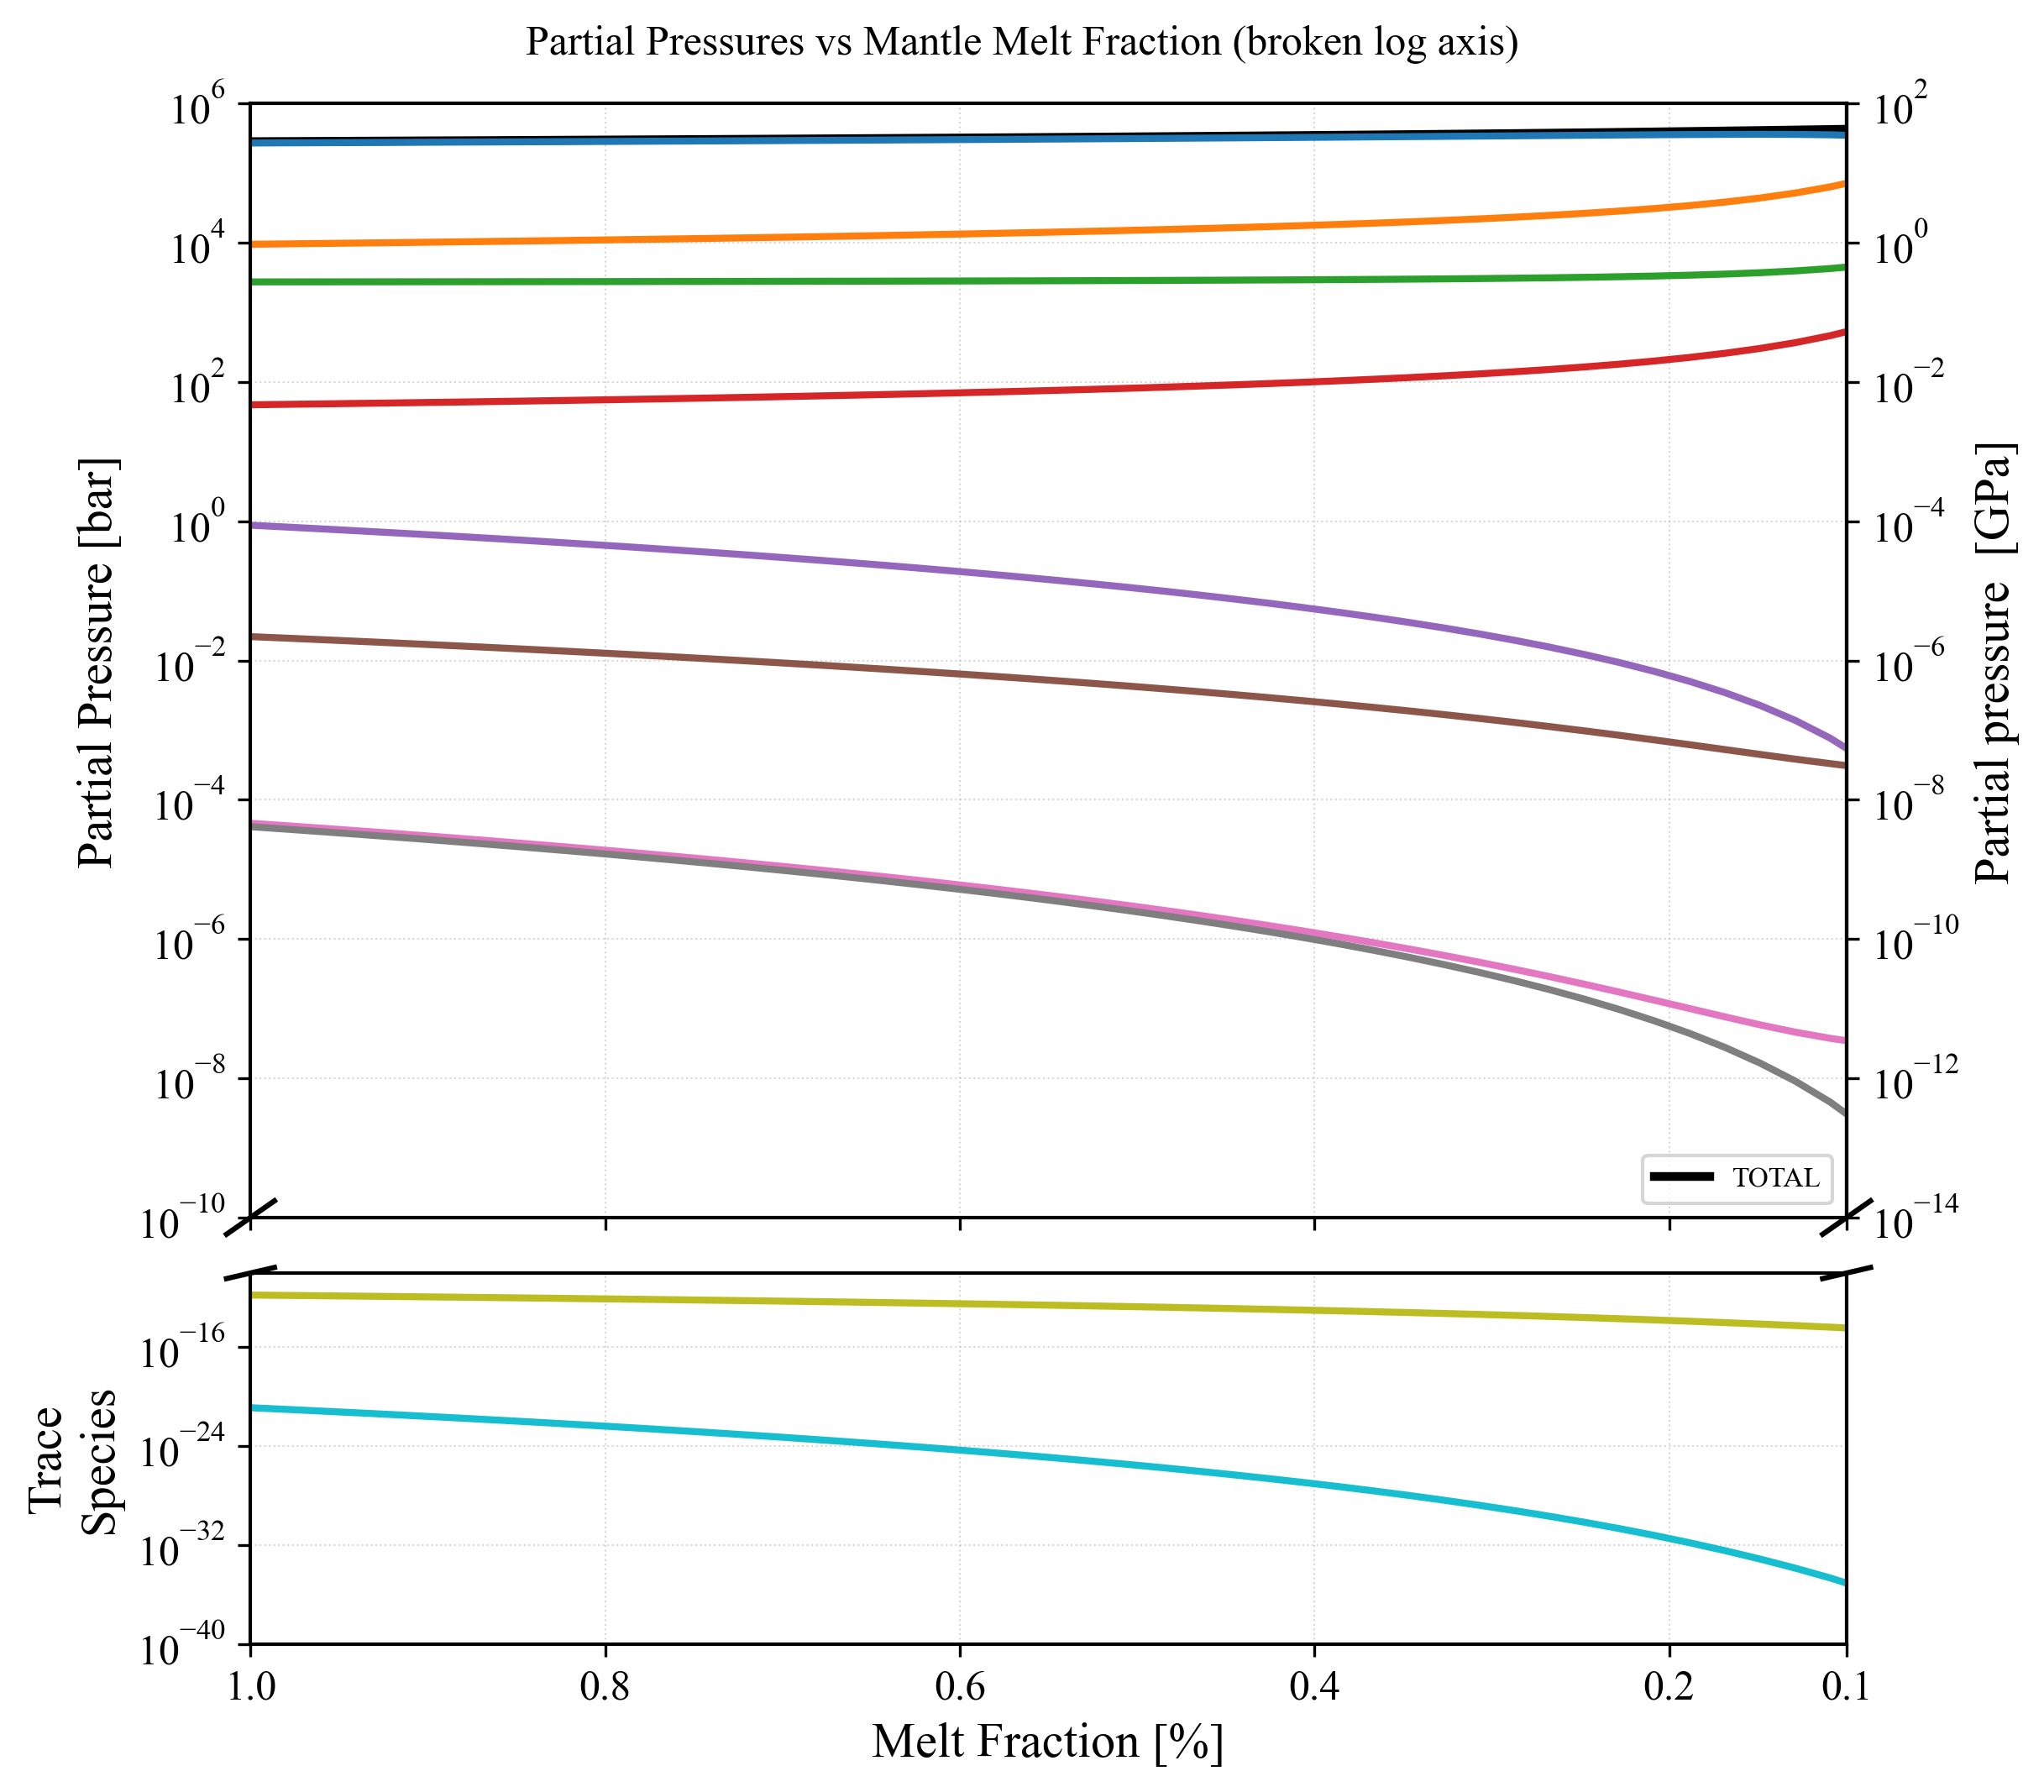

In [65]:
plot_pressure_vs_meltfraction_broken_axis("MELTSBEITCHNEW.xlsx")

In [12]:
def plot_pressure_vs_meltfraction_broken_axis(file):
    set_master_nature_style()

    CANDIDATE_SHEETS = [
        'H2O_g','CO2_g','CH4_g','H2_g','CO_g',
        'N2_g','H3N_g','He_g',"O2_g",'CHN_g'
    ]

    SPECIES_COLORS = {
        "H2O_g": "#1f77b4",
        "CO2_g": "#ff7f0e",
        "CH4_g": "#2ca02c",
        "H2_g":  "#d62728",
        "CO_g":  "#9467bd",
        "N2_g":  "#8c564b",
        "H3N_g":"#e377c2",
        "He_g": "#7f7f7f",
        "CHN_g":"#bcbd22",
        "O2_g": "#17becf",
    }

    # --- Label mapping ---
    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N": return "NH3"
        if name == "CHN": return "HCN"
        return name

    # ------------------------------------------------------
    # Load melt fraction axis
    # ------------------------------------------------------
    planet = pd.read_excel(file, sheet_name="planet")
    X = planet["mantle_melt_fraction"].to_numpy() * 100
    order = np.argsort(X)
    X = X[order]

    # ------------------------------------------------------
    # Detect available species
    # ------------------------------------------------------
    xls = pd.ExcelFile(file)
    available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

    # ------------------------------------------------------
    # Load species pressures
    # ------------------------------------------------------
    species_pressures = {}
    for s in available:
        df = pd.read_excel(file, sheet_name=s)
        if "pressure" in df.columns:
            species_pressures[s] = df["pressure"].to_numpy()[order]

    # Total atmospheric pressure
    atm = pd.read_excel(file, sheet_name="atmosphere")
    Ptot = atm["pressure"].to_numpy()[order]

    # Sort by importance
    sorted_species = sorted(
        species_pressures.keys(),
        key=lambda k: np.nanmax(species_pressures[k]),
        reverse=True
    )

    # ------------------------------------------------------
    # BROKEN AXIS PANELS  
    # ------------------------------------------------------
    fig, (ax_upper, ax_lower) = plt.subplots(
        2, 1,
        sharex=True,
        figsize=(8,7),
        dpi=300,
        height_ratios=[3,1],
        layout="constrained"
    )

    # Pressure ranges
    upper_min, upper_max = 1e-10, 1e6
    lower_min, lower_max = 1e-40, 1e-10

    # ------------------------------------------------------
    # UPPER PANEL
    # ------------------------------------------------------
    ax_upper.plot(X, Ptot, lw=2.5, color="black", label="TOTAL")

    for s in sorted_species:
        ax_upper.plot(
            X,
            species_pressures[s],
            lw=2.5,
            color=SPECIES_COLORS.get(s, "gray"),
            label=map_name(s)
        )

    ax_upper.set_yscale("log")
    ax_upper.set_ylim(upper_min, upper_max)
    ax_upper.set_ylabel("Partial Pressure [bar]")

    apply_secondary_gpa_axis(ax_upper)

    ax_upper.legend(
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.20, 0.5),
        fontsize=12
    )

    # ------------------------------------------------------
    # LOWER PANEL (trace species)
    # ------------------------------------------------------
    for s in sorted_species:
        ax_lower.plot(
            X,
            species_pressures[s],
            lw=2,
            color=SPECIES_COLORS.get(s, "gray")
        )

    ax_lower.set_yscale("log")
    ax_lower.set_ylim(lower_min, lower_max)
    ax_lower.set_ylabel("Trace Species [bar]")
    ax_lower.set_xlabel("Mantle Melt Fraction [%]")

    apply_secondary_gpa_axis(ax_lower)

    # ------------------------------------------------------
    # X-axis formatting
    # ------------------------------------------------------
    ax_lower.set_xlim([10, 100])
    ax_lower.invert_xaxis()

    xticks = [100, 75, 50, 25, 10]
    ax_lower.set_xticks(xticks)
    ax_lower.set_xticklabels([f"{t:g}" for t in xticks])

    # ------------------------------------------------------
    # Title
    # ------------------------------------------------------
    fig.suptitle(
        "Partial Pressures vs Mantle Melt Fraction (Broken Log Axis)",
        fontsize=20, ha="center", x=0.45, y=1.05
    )

    plt.show()


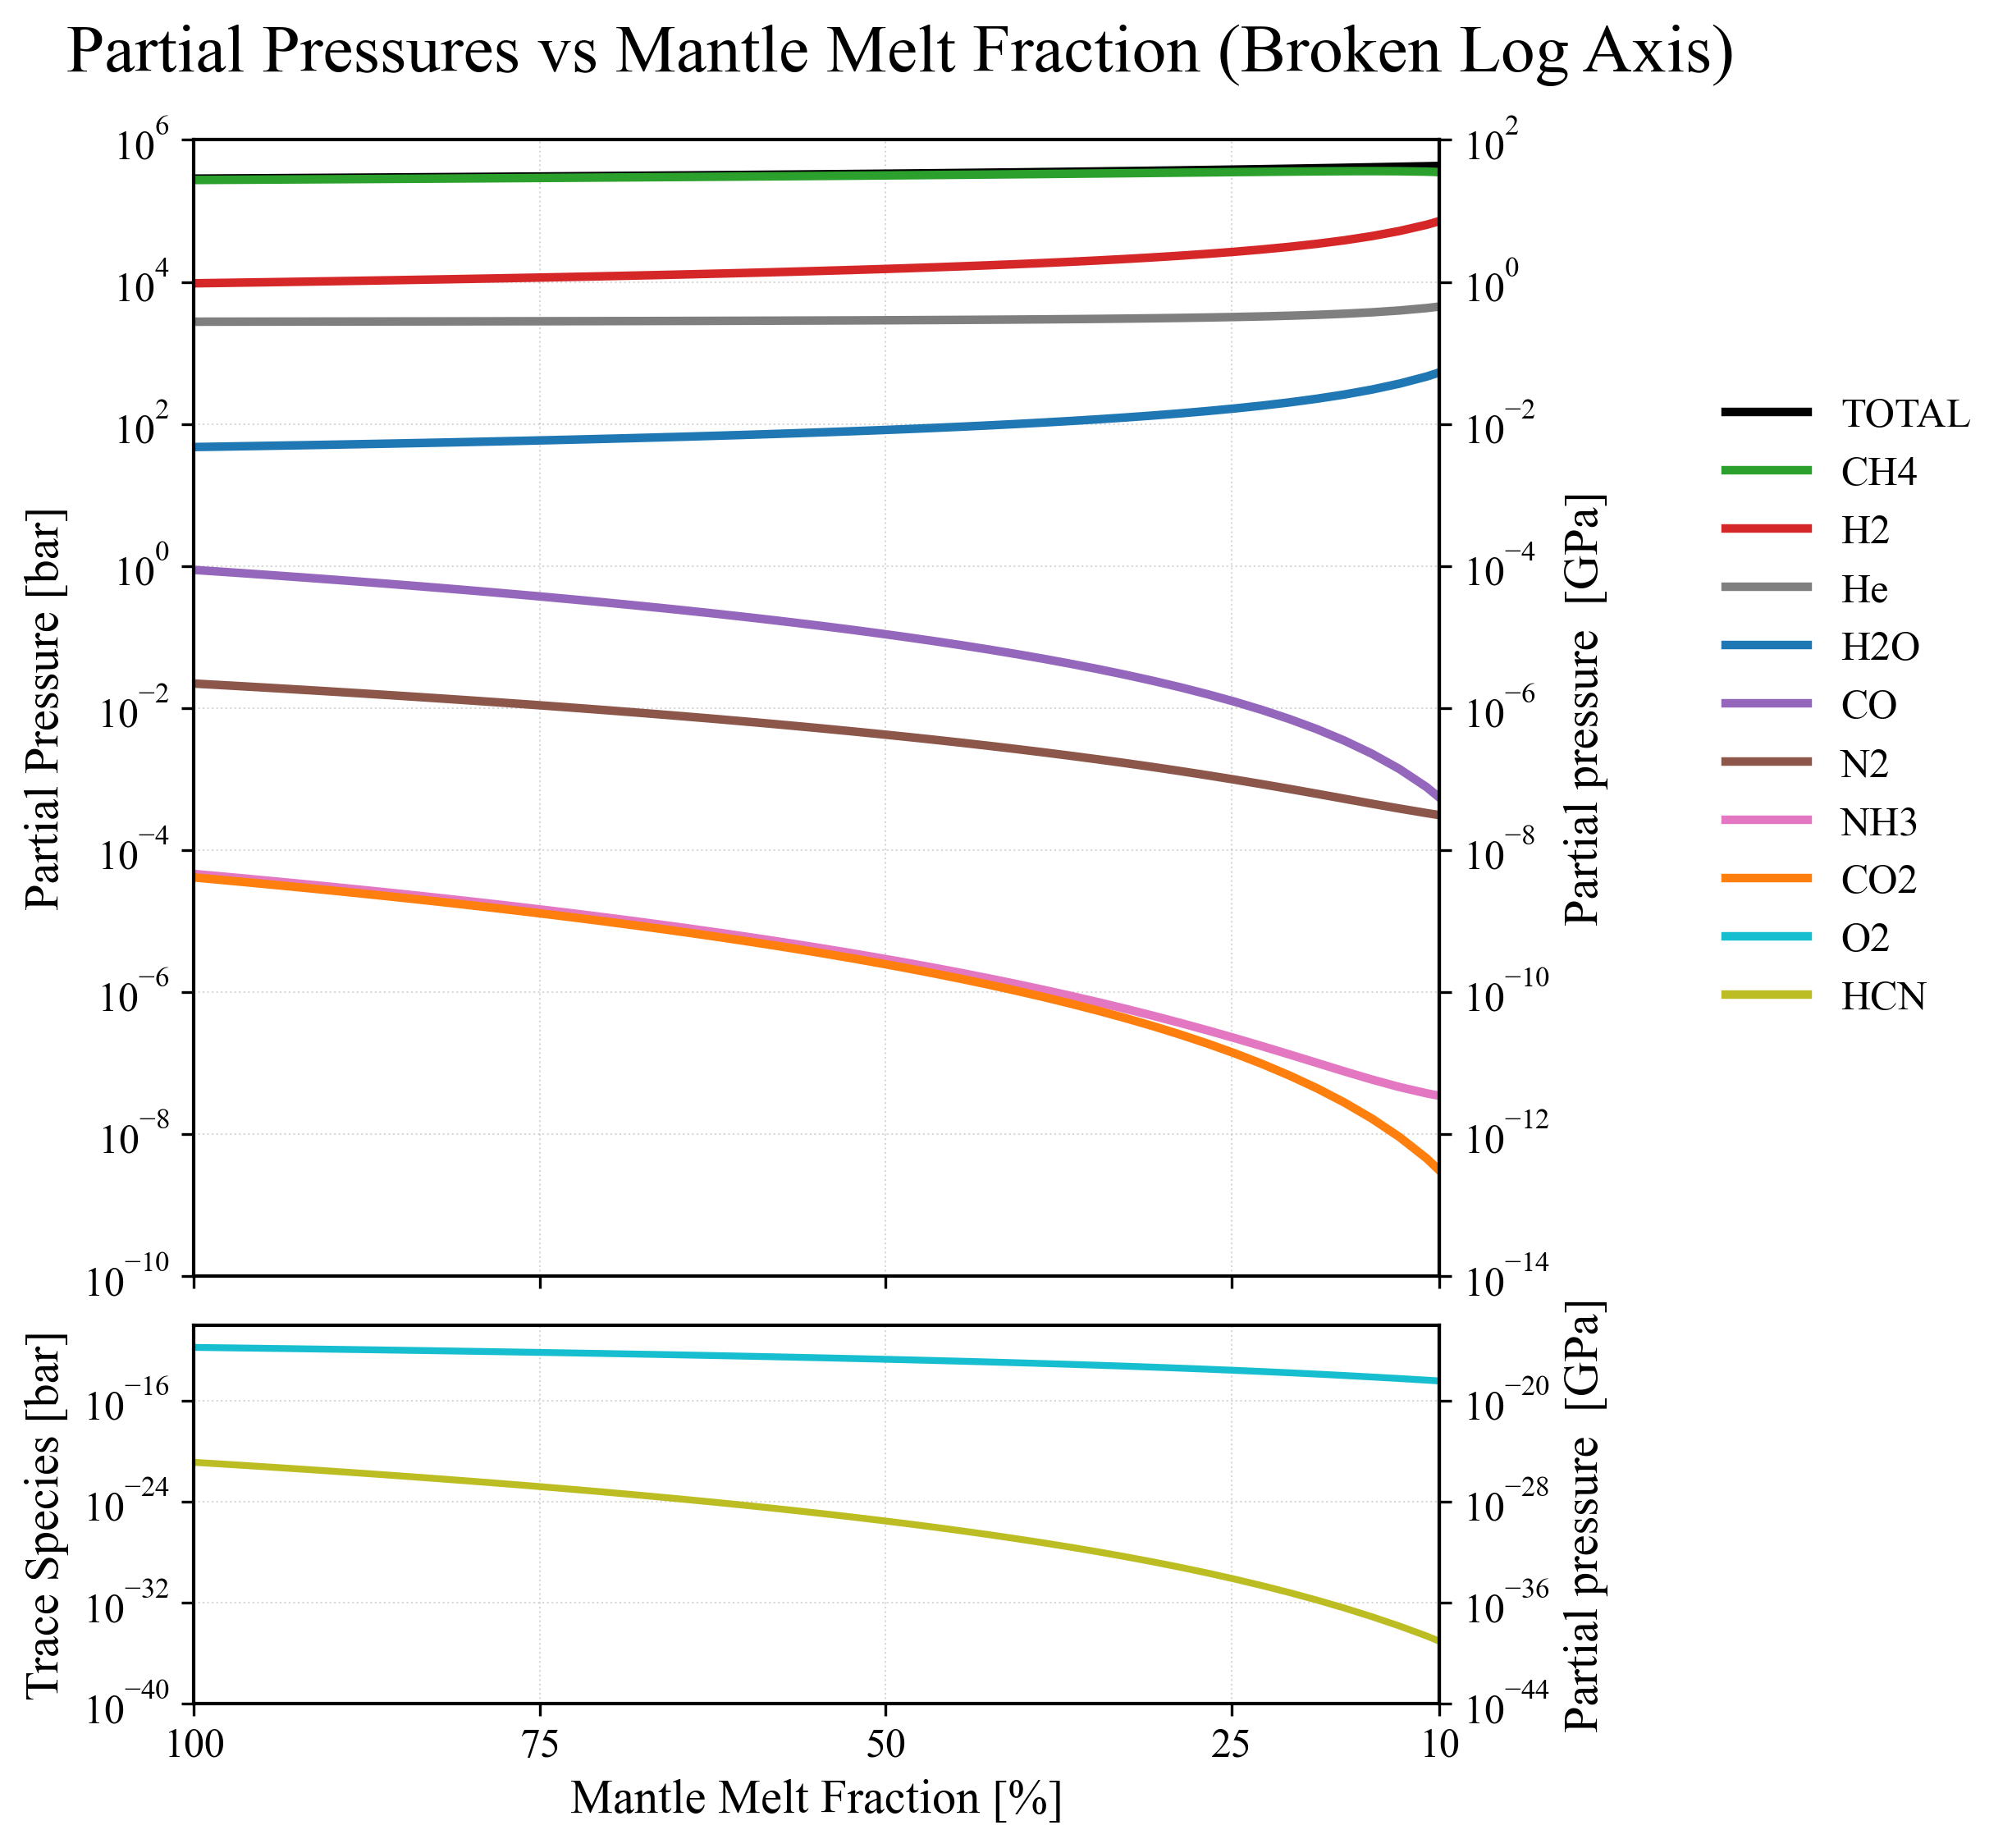

In [13]:
plot_pressure_vs_meltfraction_broken_axis("MELTSBEITCHNEW.xlsx")

In [116]:
def plot_pressure_vs_temperature_broken_axis(file):
    set_master_nature_style()

    CANDIDATE_SHEETS = [
        "H2_g","H2O_g","CO_g","CO2_g",
        "CH4_g","N2_g","H3N_g","He_g","O2_g","CHN_g"
    ]

    SPECIES_COLORS = {
        "H2O_g": "#1f77b4",
        "CO2_g": "#ff7f0e",
        "CH4_g": "#2ca02c",
        "H2_g":  "#d62728",
        "CO_g":  "#9467bd",
        "N2_g":  "#8c564b",
        "H3N_g": "#e377c2",
        "He_g":  "#7f7f7f",
        "CHN_g": "#bcbd22",
        "O2_g":  "#17becf",
    }

    # --- Label mapping ---
    def map_name(sheet):
        name = sheet.replace("_g", "")
        if name == "H3N": return "NH3"
        if name == "CHN": return "HCN"
        return name

    # ------------------------------------------------------
    # Load temperature axis
    # ------------------------------------------------------
    planet = pd.read_excel(file, sheet_name="planet")
    T = planet["surface_temperature"].to_numpy()
    order = np.argsort(T)
    T = T[order]

    # ------------------------------------------------------
    # Detect species sheets
    # ------------------------------------------------------
    xls = pd.ExcelFile(file)
    available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

    # ------------------------------------------------------
    # Load species pressures
    # ------------------------------------------------------
    species_pressures = {}
    for s in available:
        df = pd.read_excel(file, sheet_name=s)
        if "pressure" in df.columns:
            species_pressures[s] = df["pressure"].to_numpy()[order]

    # Total pressure
    atm = pd.read_excel(file, sheet_name="atmosphere")
    Ptot = atm["pressure"].to_numpy()[order]

    # Sort by importance
    sorted_species = sorted(
        species_pressures.keys(),
        key=lambda k: np.nanmax(species_pressures[k]),
        reverse=True
    )

    # ------------------------------------------------------
    # BROKEN AXIS PANELS  
    # ------------------------------------------------------
    fig, (ax_upper, ax_lower) = plt.subplots(
        2, 1,
        sharex=True,
        figsize=(8,7),
        dpi=300,
        height_ratios=[3,1],
        layout="constrained"
    )

    # Pressure ranges
    upper_min, upper_max = 1e-8, 1e6
    lower_min, lower_max = 1e-32, 1e-7

    # ------------------------------------------------------
    # UPPER PANEL
    # ------------------------------------------------------
    ax_upper.plot(T, Ptot, lw=2.5, color="black", label="TOTAL")

    for s in sorted_species:
        ax_upper.plot(
            T, species_pressures[s],
            color=SPECIES_COLORS.get(s, "gray"),
            lw=2.5,
            label=map_name(s)
        )

    ax_upper.set_yscale("log")
    ax_upper.set_ylim(upper_min, upper_max)
    ax_upper.set_ylabel("Partial Pressure [bar]")

    # Secondary GPa axis
    apply_secondary_gpa_axis(ax_upper)

    # Legend positioned same as melt-fraction version
    ax_upper.legend(
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.20, 0.5),
        fontsize=12
    )

    # ------------------------------------------------------
    # LOWER PANEL (trace species)
    # ------------------------------------------------------
    for s in sorted_species:
        ax_lower.plot(
            T, species_pressures[s],
            lw=2,
            color=SPECIES_COLORS.get(s, "gray")
        )

    ax_lower.set_yscale("log")
    ax_lower.set_ylim(lower_min, lower_max)
    ax_lower.set_ylabel("Trace Species [bar]")
    ax_lower.set_xlabel("Surface Temperature [K]")

    apply_secondary_gpa_axis(ax_lower)

    # ------------------------------------------------------
    # X-axis formatting
    # ------------------------------------------------------
    ax_lower.set_xlim([1800, 3500])
    ax_lower.set_xticks(np.arange(1800, 3600, 200))
    ax_lower.set_xticklabels([f"{t:g}" for t in np.arange(1800, 3600, 200)])

    # ------------------------------------------------------
    # Title
    # ------------------------------------------------------
    fig.suptitle(
        "Partial Pressures vs Surface Temperature (Broken Log Axis)",
        fontsize=20, ha="center", x=0.45, y=1.05
    )

    plt.show()


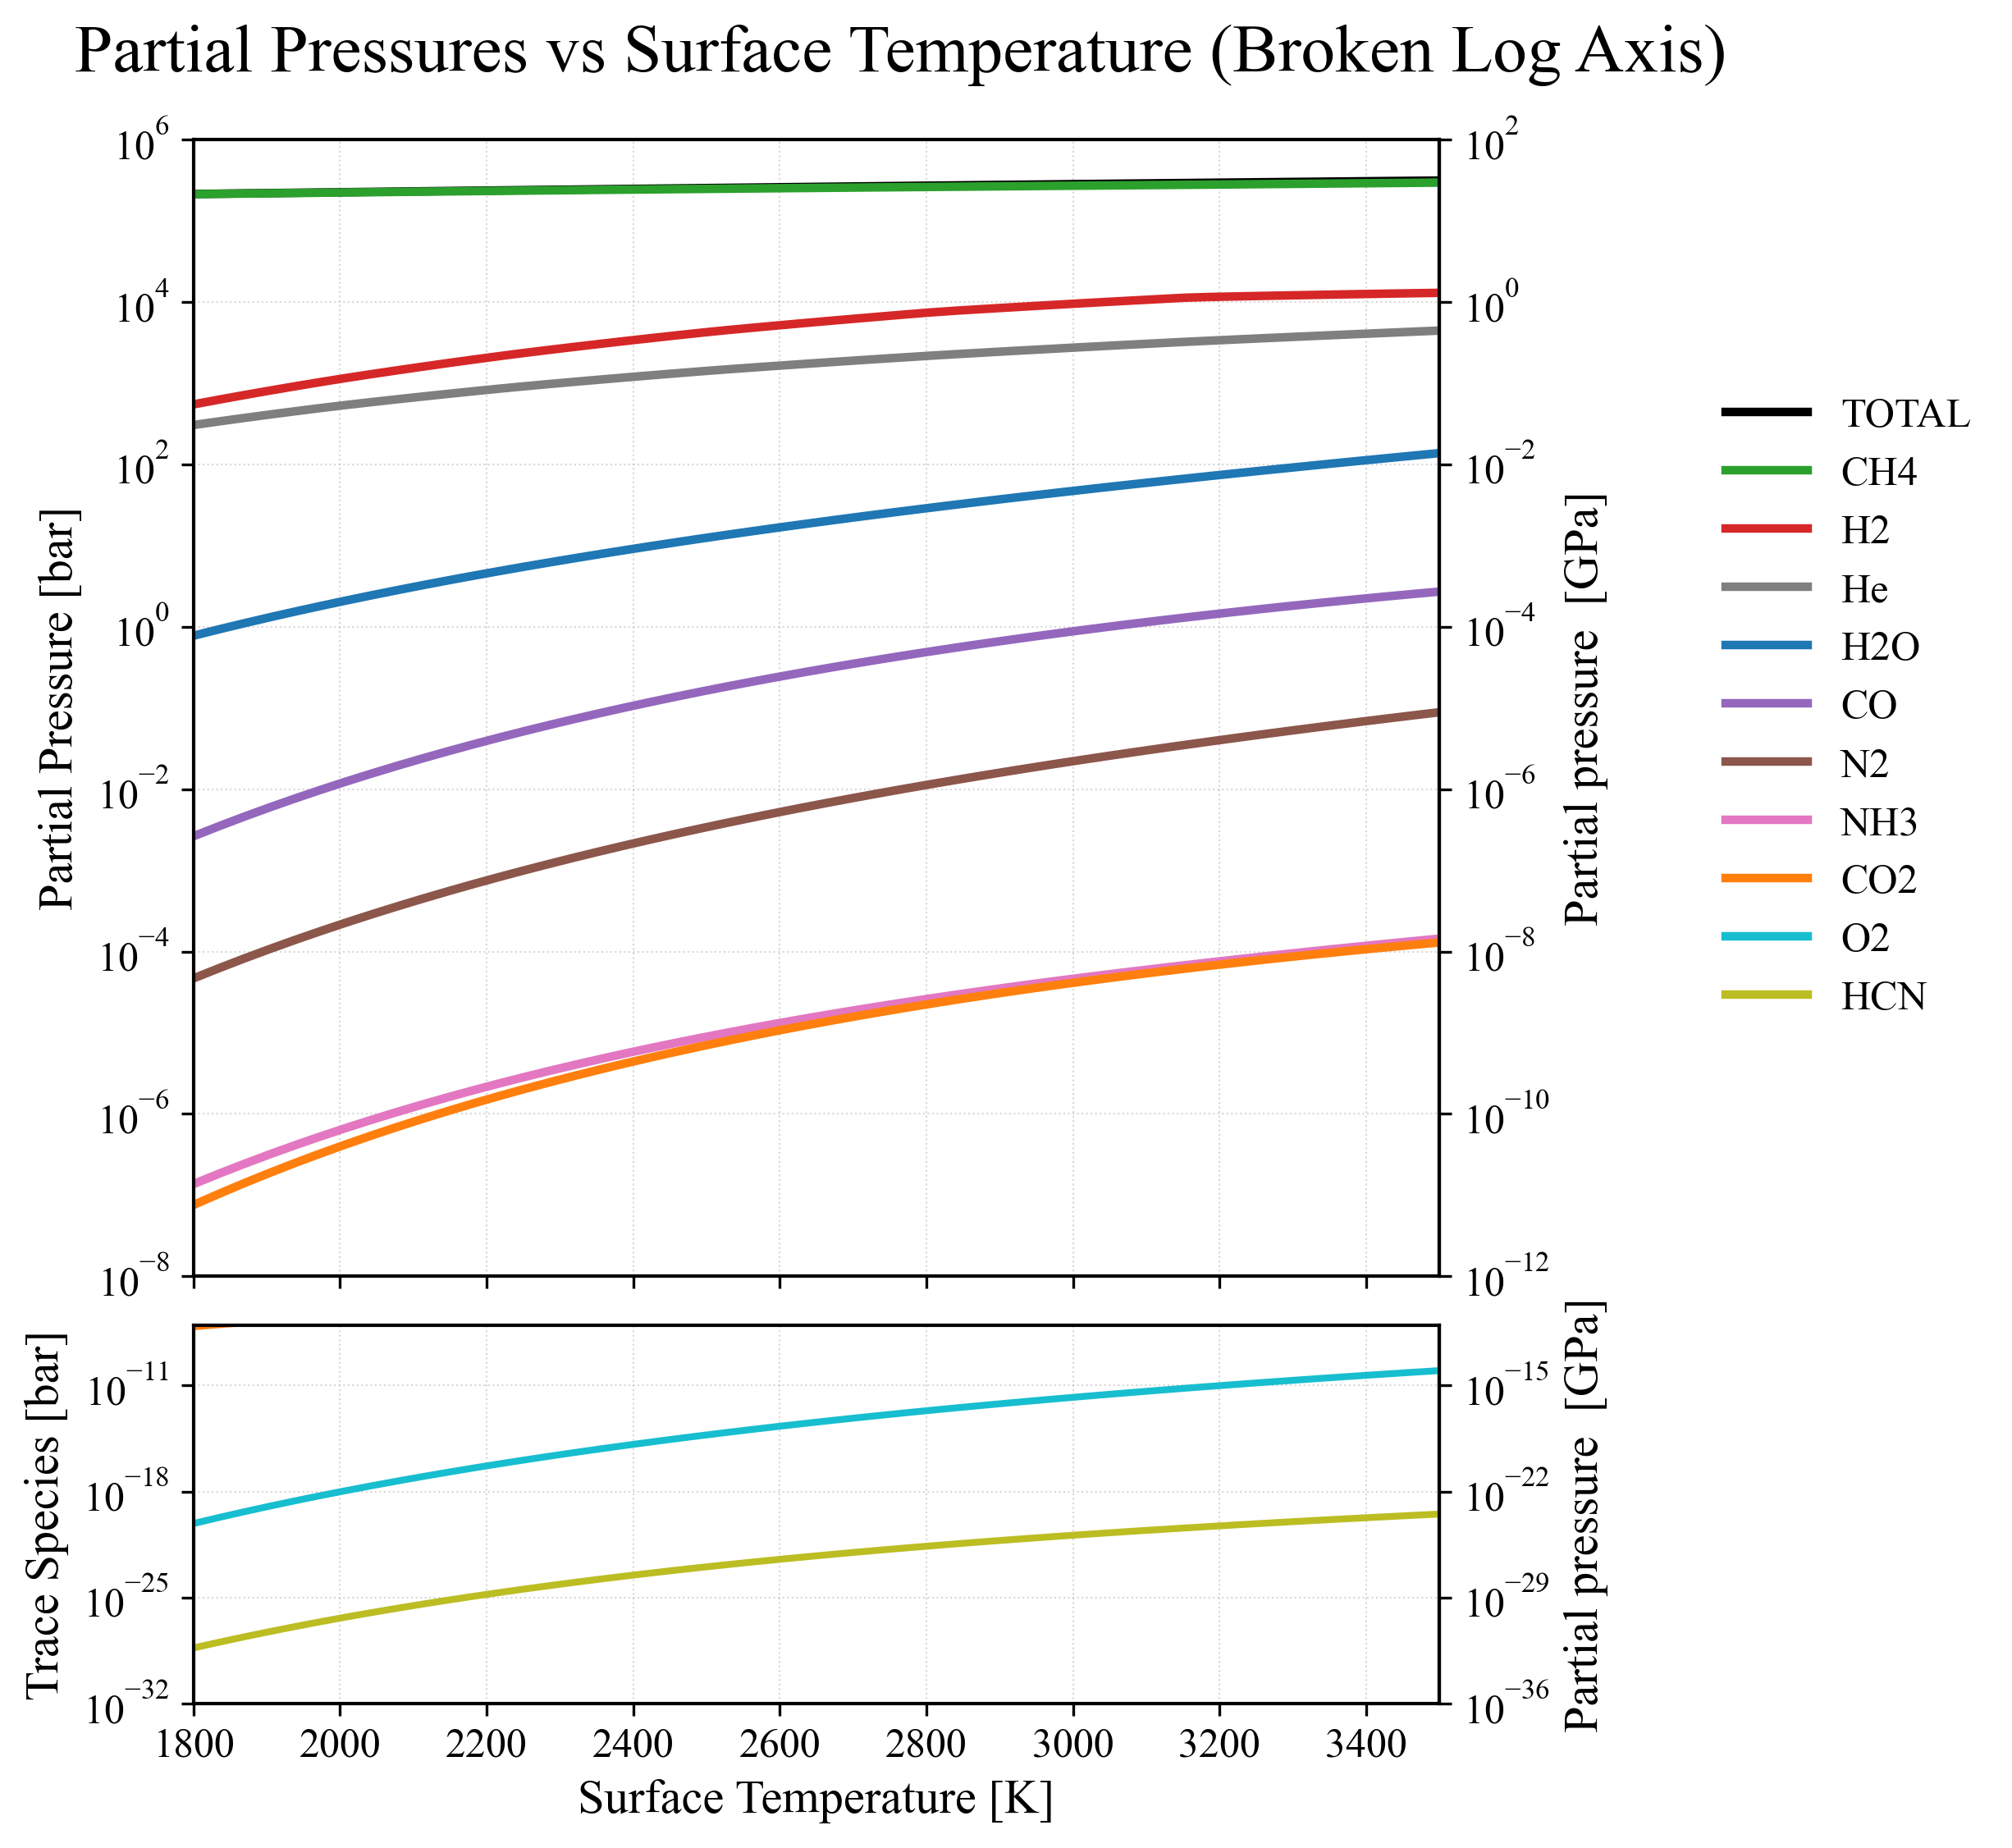

In [117]:
plot_pressure_vs_temperature_broken_axis("MOOOOOR.xlsx")